## PART 1: load pre-trained U-Net

In [1]:
# ====== CONFIGURATION ======
from pathlib import Path

# 1) Data paths (CHANGE THESE)
DATA_ROOT = Path("../Pytorch-UNet/dataset_split/train")  # root folder for your segmentation dataset
IMAGES_DIR = DATA_ROOT / "imgs"       # folder with input images
MASKS_DIR = DATA_ROOT / "masks"       # folder with corresponding masks

# 2) Pretrained model config
MODEL_SOURCE = "local"  # "hub" or "local"

# If using torch.hub:
#HUB_REPO = "milesial/Pytorch-UNet"
#HUB_MODEL_NAME = "unet_carvana"  # entry point defined in the repo
#HUB_SCALE = 0.5                  # 0.5 or 1.0 (as discussed earlier)

# If using local checkpoint:
#   - Example: Path("./checkpoints/CP_best.pth")
LOCAL_CHECKPOINT_PATH = Path("mri_checkpoint_epoch100_88.pth")

# 3) Input image size for inference (model is fully convolutional, but keep multiples of 16)
IMG_SIZE = (512, 512)  # (width, height)

# 4) Device
import torch
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)
print("Checkpoint:", LOCAL_CHECKPOINT_PATH.resolve())


Using device: cuda
Checkpoint: /home/jovyan/pruning-datavol-1/PROFILING/mri_checkpoint_epoch100_88.pth


In [2]:
import os

import numpy as np
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import matplotlib.pyplot as plt


In [3]:
# at the top of the notebook, after sys.path append to repo root if needed:
#from hubconf import unet_carvana
#
#def load_unet_model_local_from_checkpoint(
#    checkpoint_path: Path,
#    scale: float,
#    device: torch.device,
#) -> nn.Module:
#    # Create the exact same model as the hub entrypoint, but without loading weights
#    model = unet_carvana(pretrained=False, scale=scale)
#
#    state = torch.load(checkpoint_path, map_location="cpu")
#    model.load_state_dict(state)
#
#    model.to(device)
#    model.eval()
#    for p in model.parameters():
#        p.requires_grad = False
#    return model
#
#model = load_unet_model_local_from_checkpoint(
#    LOCAL_CHECKPOINT_PATH, HUB_SCALE, DEVICE
#)


ModuleNotFoundError: No module named 'hubconf'

### mri adapted


In [3]:
import sys
from pathlib import Path

REPO_ROOT = Path("/home/jovyan/pruning-datavol-1/Pytorch-UNet")
sys.path.append(str(REPO_ROOT))


In [4]:
from unet.unet_model import UNet

def load_unet_model_local_from_checkpoint(
    checkpoint_path: Path,
    device: torch.device,
) -> nn.Module:

    # MUST match training exactly
    model = UNet(
        n_channels=3,
        n_classes=2,
        bilinear=False   # learned upsampling
    )

    
    state = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if "mask_values" in state:
        del state["mask_values"]

    if "model_state_dict" in state:
        state = state["model_state_dict"]
    elif "state_dict" in state:
        state = state["state_dict"]


   

    model.load_state_dict(state)

    model.to(device)
    model.eval()

    for p in model.parameters():
        p.requires_grad = False

    return model


model = load_unet_model_local_from_checkpoint(
    LOCAL_CHECKPOINT_PATH,
    DEVICE
)


/opt/conda/envs/unet/lib/python3.10/site-packages/torch/_utils.py:831: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


In [5]:
import logging
import numpy as np
import torch
from PIL import Image
from functools import lru_cache
from functools import partial
from itertools import repeat
from multiprocessing import Pool
from os import listdir
from os.path import splitext, isfile, join
from pathlib import Path
from torch.utils.data import Dataset
from tqdm import tqdm


def load_image(filename):
    """Load image supporting various formats including .tif for brain MRI data"""
    ext = splitext(filename)[1].lower()
    if ext == '.npy':
        return Image.fromarray(np.load(filename))
    elif ext in ['.pt', '.pth']:
        return Image.fromarray(torch.load(filename).numpy())
    else:
        return Image.open(filename)


def has_mask(idx, mask_dir, mask_suffix):
    """Check if a mask exists for a given image ID"""
    for ext in ['.tif', '.tiff', '.png', '.jpg', '.jpeg', '.npy']:
        if (mask_dir / f"{idx}{mask_suffix}{ext}").exists():
            return True
    return False


def unique_mask_values(idx, mask_dir, mask_suffix):
    """Find unique values in mask for class mapping"""
    mask_file = None
    for ext in ['.tif', '.tiff', '.png', '.jpg', '.jpeg', '.npy']:
        potential_file = list(mask_dir.glob(idx + mask_suffix + ext))
        if potential_file:
            mask_file = potential_file[0]
            break

    if mask_file is None:
        raise FileNotFoundError(f'No mask file found for ID {idx} with suffix {mask_suffix}')

    mask = np.asarray(load_image(mask_file))
    if mask.ndim == 2:
        return np.unique(mask)
    elif mask.ndim == 3:
        mask = mask.reshape(-1, mask.shape[-1])
        return np.unique(mask, axis=0)
    else:
        raise ValueError(f'Loaded masks should have 2 or 3 dimensions, found {mask.ndim}')


class BasicDataset(Dataset):
    def __init__(self, images_dir: str, mask_dir: str, scale: float = 1.0, mask_suffix: str = ''):
        self.images_dir = Path(images_dir)
        self.mask_dir = Path(mask_dir)
        assert 0 < scale <= 1, 'Scale must be between 0 and 1'
        self.scale = scale
        self.mask_suffix = mask_suffix

        all_ids = [
            splitext(file)[0]
            for file in listdir(images_dir)
            if isfile(join(images_dir, file)) and not file.startswith('.') and '_mask' not in file
        ]

        # Keep only images that have corresponding masks
        self.ids = [idx for idx in all_ids if has_mask(idx, self.mask_dir, self.mask_suffix)]
        missing = len(all_ids) - len(self.ids)
        if missing > 0:
            logging.warning(f"Skipped {missing} images without corresponding masks")

        if not self.ids:
            raise RuntimeError(f'No input files with masks found in {images_dir}')

        logging.info(f'Creating dataset with {len(self.ids)} examples')
        logging.info('Scanning mask files to determine unique values')
        with Pool() as p:
            unique = list(tqdm(
                p.imap(partial(unique_mask_values, mask_dir=self.mask_dir, mask_suffix=self.mask_suffix), self.ids),
                total=len(self.ids)
            ))

        self.mask_values = list(sorted(np.unique(np.concatenate(unique), axis=0).tolist()))
        logging.info(f'Unique mask values: {self.mask_values}')

    def __len__(self):
        return len(self.ids)

    @staticmethod
    def preprocess(mask_values, pil_img, scale, is_mask):
        w, h = pil_img.size
        newW, newH = int(scale * w), int(scale * h)
        assert newW > 0 and newH > 0, 'Scale is too small, resized images would have no pixel'
        pil_img = pil_img.resize((newW, newH), resample=Image.NEAREST if is_mask else Image.BICUBIC)
        img = np.asarray(pil_img)

        if is_mask:
            mask = np.zeros((newH, newW), dtype=np.int64)
            for i, v in enumerate(mask_values):
                if img.ndim == 2:
                    mask[img == v] = i
                else:
                    mask[(img == v).all(-1)] = i

            # FIX 2: moved here from after `return img` where it was unreachable dead code
            if mask.max() > 1:
                mask = mask // 255  # convert 255 → 1

            return mask
        else:
            if img.ndim == 2:
                img = img[np.newaxis, ...]
            else:
                img = img.transpose((2, 0, 1))
            if (img > 1).any():
                img = img / 255.0
            return img

    def __getitem__(self, idx):
        name = self.ids[idx]

        mask_file = None
        for ext in ['.tif', '.tiff', '.png', '.jpg', '.jpeg', '.npy']:
            potential_mask = list(self.mask_dir.glob(name + self.mask_suffix + ext))
            if potential_mask:
                mask_file = potential_mask
                break

        img_file = None
        for ext in ['.tif', '.tiff', '.png', '.jpg', '.jpeg', '.npy']:
            potential_img = list(self.images_dir.glob(name + ext))
            if potential_img:
                img_file = potential_img
                break

        assert img_file is not None and len(img_file) == 1, \
            f'Either no image or multiple images found for the ID {name}: {img_file}'
        assert mask_file is not None and len(mask_file) == 1, \
            f'Either no mask or multiple masks found for the ID {name}: {mask_file}'

        mask = load_image(mask_file[0])
        img = load_image(img_file[0])

        assert img.size == mask.size, \
            f'Image and mask {name} should be the same size, but are {img.size} and {mask.size}'

        #img = self.preprocess(self.mask_values, img, self.scale, is_mask=False)
        #mask = self.preprocess(self.mask_values, mask, self.scale, is_mask=True)
        img = np.array(self.preprocess(self.mask_values, img, self.scale, is_mask=False), dtype=np.float32)
        mask = np.array(self.preprocess(self.mask_values, mask, self.scale, is_mask=True), dtype=np.int64)

        # FIX 1: use np.int64 — PyTorch can infer this directly as torch.long
        # np.int32 causes "Could not infer dtype" in newer NumPy/PyTorch versions
        mask = mask.astype(np.int64)
        print(type(mask), mask.dtype, mask.shape)

        return {
            'image': torch.from_numpy(img).float().contiguous(),
            'mask': torch.from_numpy(mask).long().contiguous()
        }


class CarvanaDataset(BasicDataset):
    def __init__(self, images_dir, mask_dir, scale=1):
        super().__init__(images_dir, mask_dir, scale, mask_suffix='_mask')


class BrainMRIDataset(BasicDataset):
    """
    Brain MRI segmentation dataset:
    - grayscale images
    - supports .tif / .npy
    - explicit mask suffix
    """
    def __init__(self, images_dir, mask_dir, scale=0.5, mask_suffix='_mask'):
        super().__init__(images_dir, mask_dir, scale, mask_suffix)
        logging.info("Using BrainMRIDataset (MRI-specific assumptions)")

In [14]:
import torch
from pathlib import Path
from torch.utils.data import Dataset


mri_dataset = BrainMRIDataset(
    images_dir=IMAGES_DIR,
    mask_dir=MASKS_DIR,
    scale=0.5,          # downscale images if needed
    mask_suffix='_mask' # matches your saved mask naming
)

# Get first sample safely
sample = mri_dataset[0]

# Force proper dtype for display / inspection
image_tensor = torch.as_tensor(sample['image']).float()
mask_tensor = torch.as_tensor(sample['mask'], dtype=torch.long)

print("Image shape:", image_tensor.shape)  # C x H x W
print("Mask shape:", mask_tensor.shape)    # H x W or 1 x H x W


100%|██████████| 3184/3184 [00:00<00:00, 8726.80it/s]


<class 'numpy.ndarray'> int64 (128, 128)
Image shape: torch.Size([3, 128, 128])
Mask shape: torch.Size([128, 128])


In [16]:
#import numpy as np
#from PIL import Image
#from torch.utils.data import Dataset
#
#class CarvanaDataset(Dataset):
#    """
#    Carvana image–mask dataset.
#
#    - images:  train/*.jpg
#    - masks:   train_masks/*_mask.gif
#    """
#
#    def __init__(self, images_dir: Path, masks_dir: Path, img_size=(512, 512)):
#        self.images_dir = Path(images_dir)
#        self.masks_dir = Path(masks_dir)
#        self.img_size = img_size  # (W, H)
#
#        assert self.images_dir.is_dir(), f"{self.images_dir} does not exist"
#        assert self.masks_dir.is_dir(), f"{self.masks_dir} does not exist"
#
#        exts = {".jpg", ".jpeg"}  # Carvana train images are jpg
#        self.image_paths = sorted(
#            [p for p in self.images_dir.iterdir() if p.suffix.lower() in exts]
#        )
#        assert len(self.image_paths) > 0, f"No images found in {self.images_dir}"
#
#        # Check that masks exist
#        missing_masks = []
#        for img_path in self.image_paths:
#            stem = img_path.stem  # e.g. "00087a6bd4dc_01"
#            mask_path = self.masks_dir / f"{stem}_mask.gif"
#            if not mask_path.is_file():
#                missing_masks.append(mask_path)
#
#        if missing_masks:
#            print("Warning: some masks are missing (first 5):")
#            for m in missing_masks[:5]:
#                print("  Missing:", m)
#
#        print(f"Found {len(self.image_paths)} train images in {self.images_dir}.")
#
#    def __len__(self):
#        return len(self.image_paths)
#
#    def __getitem__(self, idx):
#        img_path = self.image_paths[idx]
#        stem = img_path.stem
#        mask_path = self.masks_dir / f"{stem}_mask.gif"
#
#        # Load image (RGB)
#        img = Image.open(img_path).convert("RGB")
#        # Load mask (GIF -> grayscale)
#        mask = Image.open(mask_path).convert("L")
#
#        # Resize for inference (originals are ~1918×1280, we keep a smaller size)
#        img = img.resize(self.img_size, resample=Image.BILINEAR)
#        mask = mask.resize(self.img_size, resample=Image.NEAREST)
#
#        # To numpy
#        img_np = np.array(img).astype(np.float32) / 255.0  # H×W×C in [0,1]
#        mask_np = np.array(mask).astype(np.float32)        # H×W, 0..255
#
#        # Binary mask 0/1 (car or background)
#        mask_np = (mask_np > 0).astype(np.float32)
#
#        # To tensors
#        img_tensor = torch.from_numpy(img_np).permute(2, 0, 1)   # C×H×W
#        mask_tensor = torch.from_numpy(mask_np).unsqueeze(0)     # 1×H×W
#
#        return img_tensor, mask_tensor, img_path.name
#

In [ ]:
dataset = CarvanaDataset(
    images_dir=IMAGES_DIR,
    masks_dir=MASKS_DIR,
    img_size=IMG_SIZE,
)

print("Total images in dataset:", len(dataset))

sample_idx = 0
img_tensor, mask_tensor, img_name = dataset[sample_idx]
print(f"Sample: {img_name}")
print("  Image tensor shape:", img_tensor.shape)
print("  Mask tensor shape :", mask_tensor.shape)


In [17]:
model.eval()

with torch.no_grad():
    input_batch = image_tensor.unsqueeze(0).to(DEVICE)  # 1×C×H×W

    logits = model(input_batch)  # 1×2×H×W

    # For 2-class output: apply softmax along channel dimension and take argmax
    probs = torch.softmax(logits, dim=1)       # 1×2×H×W
    pred_class = probs.argmax(dim=1)           # 1×H×W, values {0,1}
    pred_mask = pred_class.float()             # 1×H×W -> for plotting

# Back to CPU / numpy
img_np = image_tensor.cpu().numpy().transpose(1, 2, 0)          # H×W×C
gt_mask_np = mask_tensor.squeeze(0).cpu().numpy()             # H×W
pred_mask_np = pred_mask.squeeze(0).cpu().numpy()             # H×W


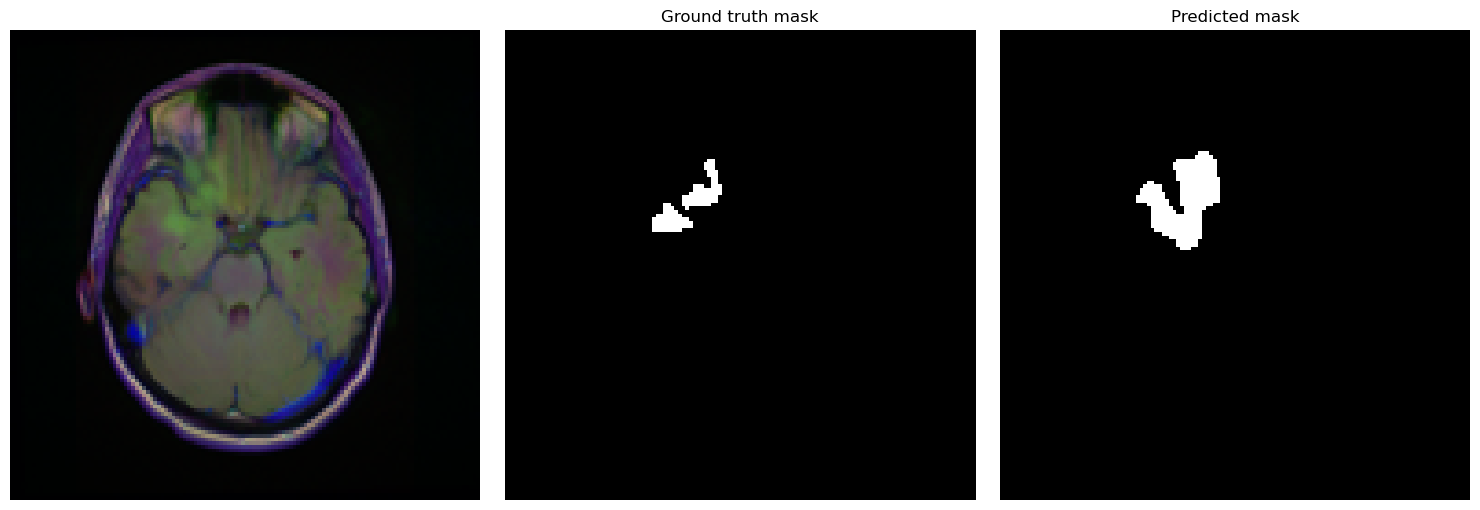

In [19]:
fig, axs = plt.subplots(1, 3, figsize=(15, 5))

axs[0].imshow(img_np)

axs[0].axis("off")

axs[1].imshow(gt_mask_np, cmap="gray")
axs[1].set_title("Ground truth mask")
axs[1].axis("off")

axs[2].imshow(pred_mask_np, cmap="gray")
axs[2].set_title("Predicted mask")
axs[2].axis("off")

plt.tight_layout()
plt.show()


=== Model A output debug ===
logits shape: (1, 2, 128, 128)
logits[bg] min/max/mean: (-1.754574179649353, 2.7127177715301514, 2.182840585708618)
logits[fg] min/max/mean: (-2.634840726852417, 1.9675379991531372, -2.1242446899414062)
p_fg (softmax) min/max/mean: (0.005122553091496229, 0.9738646149635315, 0.03017498552799225)
p_fg > 0.5 fraction: 0.01971435546875


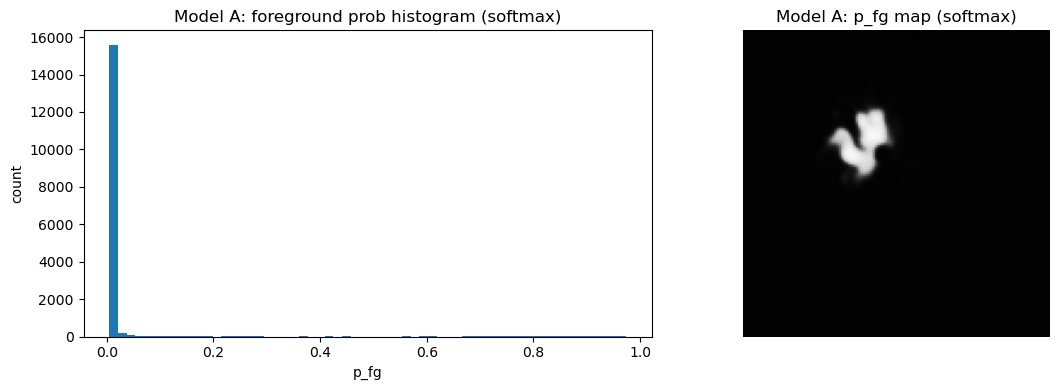

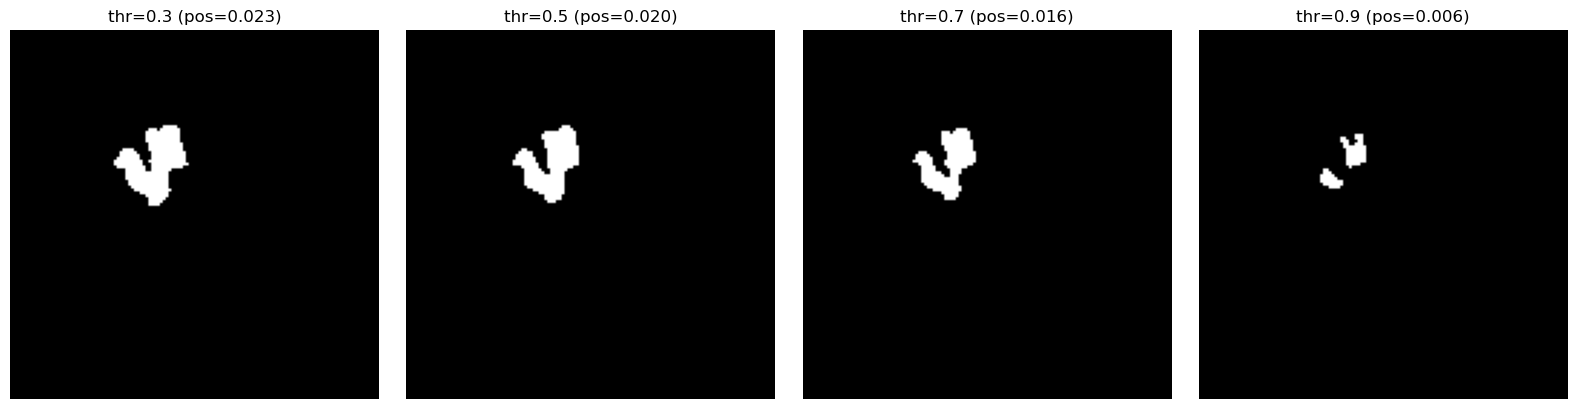

In [22]:
import torch
import numpy as np
import matplotlib.pyplot as plt

@torch.no_grad()
def debug_outputs_modelA(model, image_tensor, device, thr_list=(0.3, 0.5, 0.7, 0.9)):
    """
    Model A: output is logits with shape (1,2,H,W).
    We inspect:
      - logits stats per channel
      - softmax probabilities stats
      - foreground prob histogram
      - thresholded masks at multiple thresholds
    """
    model.eval().to(device)
    x = image_tensor.unsqueeze(0).to(device)  # 1,C,H,W

    logits = model(x)  # 1,2,H,W (logits)
    assert logits.dim() == 4 and logits.size(1) == 2, f"Expected (1,2,H,W), got {tuple(logits.shape)}"

    probs = torch.softmax(logits, dim=1)     # 1,2,H,W
    p_bg = probs[:, 0]
    p_fg = probs[:, 1]                       # foreground probability

    # ---- Print stats ----
    def stats(t): 
        return float(t.min()), float(t.max()), float(t.mean())

    print("=== Model A output debug ===")
    print("logits shape:", tuple(logits.shape))
    print("logits[bg] min/max/mean:", stats(logits[:,0]))
    print("logits[fg] min/max/mean:", stats(logits[:,1]))
    print("p_fg (softmax) min/max/mean:", stats(p_fg))
    print("p_fg > 0.5 fraction:", float((p_fg > 0.5).float().mean()))

    # ---- Plots ----
    p_fg_np = p_fg.squeeze(0).squeeze(0).detach().cpu().numpy()  # H,W

    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].hist(p_fg_np.flatten(), bins=60)
    axs[0].set_title("Model A: foreground prob histogram (softmax)")
    axs[0].set_xlabel("p_fg"); axs[0].set_ylabel("count")

    axs[1].imshow(p_fg_np, cmap="gray", vmin=0, vmax=1)
    axs[1].set_title("Model A: p_fg map (softmax)")
    axs[1].axis("off")
    plt.tight_layout()
    plt.show()

    # ---- Threshold masks ----
    n = len(thr_list)
    fig, axs = plt.subplots(1, n, figsize=(4*n, 4))
    if n == 1:
        axs = [axs]
    for ax, thr in zip(axs, thr_list):
        m = (p_fg_np > thr).astype(np.float32)
        ax.imshow(m, cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"thr={thr} (pos={m.mean():.3f})")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    return logits, probs

# USAGE:
# img_tensor is a single sample image tensor (C,H,W) from your dataset cell
logits_A, probs_A = debug_outputs_modelA(model, image_tensor, DEVICE)


## Part 2: Model wrapper & Parameters Analysis

#### global helpers + overall size

In [26]:
pip install pandas

  Using cached pytz-2025.2-py2.py3-none-any.whl.metadata (22 kB)
  Using cached tzdata-2025.3-py2.py3-none-any.whl.metadata (1.4 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 32.1 MB/s  0:00:00m0:00:010:01
Using cached pytz-2025.2-py2.py3-none-any.whl (509 kB)
Using cached tzdata-2025.3-py2.py3-none-any.whl (348 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pandas]2m2/3 [pandas]
Note: you may need to restart the kernel to use updated packages.


In [27]:
import torch
import torch.nn as nn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def count_parameters(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())


def sizeof_parameters_mb(module: nn.Module, bytes_per_param: int = 4) -> float:
    """Approximate parameter memory in MB (float32 = 4 bytes)."""
    return count_parameters(module) * bytes_per_param / (1024 ** 2)


total_params = count_parameters(model)
total_size_mb = sizeof_parameters_mb(model)

print(f"Total parameters: {total_params:,}")
print(f"Approx. model size (float32): {total_size_mb:.2f} MB")


Total parameters: 31,037,698
Approx. model size (float32): 118.40 MB


#### block shapes

In [30]:
def inspect_unet_blocks_milesial(model: nn.Module,
                                 input_size=(1, 3, 512, 512),
                                 device=None):
    """
    Forward one dummy input through the milesial/Pytorch-UNet and
    record shapes of key blocks.

    Assumes attributes: inc, down1..down4, up1..up4, outc.
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = model.to(device)
    model.eval()

    with torch.no_grad():
        x = torch.randn(*input_size, device=device)

        # Encoder
        x1 = model.inc(x)       # enc1
        x2 = model.down1(x1)    # enc2
        x3 = model.down2(x2)    # enc3
        x4 = model.down3(x3)    # enc4
        x5 = model.down4(x4)    # bottleneck

        # Decoder
        y4 = model.up1(x5, x4)  # dec4
        y3 = model.up2(y4, x3)  # dec3
        y2 = model.up3(y3, x2)  # dec2
        y1 = model.up4(y2, x1)  # dec1

        out = model.outc(y1)    # out_conv

    shapes = {
        "input":      tuple(x.shape),
        "enc1":       tuple(x1.shape),
        "enc2":       tuple(x2.shape),
        "enc3":       tuple(x3.shape),
        "enc4":       tuple(x4.shape),
        "bottleneck": tuple(x5.shape),
        "dec4":       tuple(y4.shape),
        "dec3":       tuple(y3.shape),
        "dec2":       tuple(y2.shape),
        "dec1":       tuple(y1.shape),
        "out":        tuple(out.shape),
    }
    return shapes


shapes_128 = inspect_unet_blocks_milesial(model, input_size=(1, 3, 128, 128), device=DEVICE)

print("Block output shapes for input 1×3×512×512:")
for name, shape in shapes_128.items():
    print(f"{name:11s} -> {shape}")


Block output shapes for input 1×3×512×512:
input       -> (1, 3, 128, 128)
enc1        -> (1, 64, 128, 128)
enc2        -> (1, 128, 64, 64)
enc3        -> (1, 256, 32, 32)
enc4        -> (1, 512, 16, 16)
bottleneck  -> (1, 1024, 8, 8)
dec4        -> (1, 512, 16, 16)
dec3        -> (1, 256, 32, 32)
dec2        -> (1, 128, 64, 64)
dec1        -> (1, 64, 128, 128)
out         -> (1, 2, 128, 128)


In [32]:
import torch
import torch.nn as nn

def _tensor_nbytes(shape, bytes_per_elem=4):
    if not (isinstance(shape, tuple) and all(isinstance(x, int) for x in shape)):
        return None
    n = 1
    for d in shape:
        n *= d
    return n * bytes_per_elem

def summarize_layers_io(
    model: nn.Module,
    input_size=(1, 3, 512, 512),
    device=None,
    bytes_per_elem=4,   # float32
    show_bn=False,
    show_relu=False,
    show_pool=False,
):
    """
    Prints one row per interesting layer with:
      - in->out channels, kernel/stride/pad
      - out_shape and Cout
      - params
      - activation size (MB)
    Also implicitly reveals skip concat convs because you'll see convs with large in_channels.
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = model.to(device).eval()

    # Forward output shapes captured by module name
    out_shapes = {}
    hooks = []

    def hook_fn(name):
        def _hook(_m, _inp, out):
            if hasattr(out, "shape"):
                out_shapes[name] = tuple(out.shape)
            elif isinstance(out, (tuple, list)) and len(out) and hasattr(out[0], "shape"):
                out_shapes[name] = tuple(out[0].shape)
            else:
                out_shapes[name] = None
        return _hook

    for name, m in model.named_modules():
        if name == "":
            continue
        hooks.append(m.register_forward_hook(hook_fn(name)))

    with torch.no_grad():
        x = torch.randn(*input_size, device=device)
        _ = model(x)

    for h in hooks:
        h.remove()

    rows = []

    for name, m in model.named_modules():
        if name == "":
            continue

        is_conv = isinstance(m, nn.Conv2d)
        is_deconv = isinstance(m, nn.ConvTranspose2d)
        is_bn = isinstance(m, nn.BatchNorm2d)
        is_relu = isinstance(m, nn.ReLU)
        is_pool = isinstance(m, (nn.MaxPool2d, nn.AvgPool2d))

        if not (is_conv or is_deconv or (show_bn and is_bn) or (show_relu and is_relu) or (show_pool and is_pool)):
            continue

        oshape = out_shapes.get(name, None)
        out_ch = oshape[1] if (isinstance(oshape, tuple) and len(oshape) >= 2) else None

        nb = _tensor_nbytes(oshape, bytes_per_elem=bytes_per_elem)
        act_mb = (nb / (1024**2)) if nb is not None else None

        params = sum(p.numel() for p in m.parameters(recurse=False))

        # metadata
        if is_conv:
            meta = f"{m.in_channels}->{m.out_channels} k={tuple(m.kernel_size)} s={tuple(m.stride)} p={tuple(m.padding)}"
        elif is_deconv:
            meta = f"{m.in_channels}->{m.out_channels} k={tuple(m.kernel_size)} s={tuple(m.stride)} p={tuple(m.padding)}"
        elif is_bn:
            meta = f"BN(nf={m.num_features})"
        elif is_pool:
            k = getattr(m, "kernel_size", None)
            s = getattr(m, "stride", None)
            p = getattr(m, "padding", None)
            meta = f"POOL k={k} s={s} p={p}"
        else:
            meta = m.__class__.__name__

        block = name.split(".")[0]

        rows.append({
            "block": block,
            "name": name,
            "type": m.__class__.__name__,
            "meta": meta,
            "out_shape": oshape,
            "out_ch": out_ch,
            "params": params,
            "act_mb": act_mb,
        })

    def trunc(s, w):
        s = str(s)
        return s if len(s) <= w else s[:w-3] + "..."

    # Print
    print(f"{'block':<6} | {'layer':<55} | {'type':<15} | {'in->out / details':<34} | {'out_shape':<18} | {'Cout':>4} | {'params':>10} | {'act(MB)':>8}")
    print("-"*175)

    for r in rows:
        act_str = f"{r['act_mb']:.2f}" if r["act_mb"] is not None else ""
        cout_str = str(r["out_ch"]) if r["out_ch"] is not None else ""
        print(
            f"{r['block']:<6} | "
            f"{trunc(r['name'],55):<55} | "
            f"{r['type']:<15} | "
            f"{trunc(r['meta'],34):<34} | "
            f"{trunc(r['out_shape'],18):<18} | "
            f"{cout_str:>4} | "
            f"{r['params']:>10,} | "
            f"{act_str:>8}"
        )

    return rows

# === USAGE ===
rows = summarize_layers_io(
    model,
    input_size=(1, 3, 128, 128),
    device=DEVICE,
    show_bn=False,   # set True if you want BN rows too
    show_relu=False,
    show_pool=False,
)


block  | layer                                                   | type            | in->out / details                  | out_shape          | Cout |     params |  act(MB)
-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
inc    | inc.double_conv.0                                       | Conv2d          | 3->64 k=(3, 3) s=(1, 1) p=(1, 1)   | (1, 64, 128, 128)  |   64 |      1,728 |     4.00
inc    | inc.double_conv.3                                       | Conv2d          | 64->64 k=(3, 3) s=(1, 1) p=(1, 1)  | (1, 64, 128, 128)  |   64 |     36,864 |     4.00
down1  | down1.maxpool_conv.1.double_conv.0                      | Conv2d          | 64->128 k=(3, 3) s=(1, 1) p=(1, 1) | (1, 128, 64, 64)   |  128 |     73,728 |     2.00
down1  | down1.maxpool_conv.1.double_conv.3                      | Conv2d          | 128->128 k=(3, 3) s=(1, 1) p=(1... | (1, 128, 64, 6

#### per-block params + DataFrame

In [33]:
# Mapping from logical block name to list of submodules in the milesial UNet
UNET_BLOCK_MODULES = {
    "enc1":       ["inc"],
    "enc2":       ["down1"],
    "enc3":       ["down2"],
    "enc4":       ["down3"],
    "bottleneck": ["down4"],
    "dec4":       ["up1"],
    "dec3":       ["up2"],
    "dec2":       ["up3"],
    "dec1":       ["up4"],
    "out_conv":   ["outc"],
}


def params_per_block(model: nn.Module, block_modules: dict) -> dict:
    """
    Count parameters per logical block given a mapping:
    block_name -> [submodule_name, ...].
    """
    out = {}
    for block_name, sub_names in block_modules.items():
        n = 0
        for sub in sub_names:
            submodule = getattr(model, sub)
            n += count_parameters(submodule)
        out[block_name] = n
    return out


params_per_block_dict = params_per_block(model, UNET_BLOCK_MODULES)

print("Per-block parameter counts:")
for name, n_params in params_per_block_dict.items():
    print(f"{name:11s}: {n_params:,}")

print("\nCheck sum vs total:")
print(f"Sum of blocks: {sum(params_per_block_dict.values()):,}")
print(f"Total model : {total_params:,}")

# Build a DataFrame in a fixed order (encoder → bottleneck → decoder)
blocks_order = ["enc1", "enc2", "enc3", "enc4",
                "bottleneck",
                "dec4", "dec3", "dec2", "dec1", "out_conv"]

rows = []
for b in blocks_order:
    n = params_per_block_dict[b]
    rows.append({
        "block": b,
        "params": n,
        "params_M": n / 1e6,
    })

df_params_blocks = pd.DataFrame(rows)
total_params_blocks = df_params_blocks["params"].sum()
df_params_blocks["share_percent"] = 100.0 * df_params_blocks["params"] / (total_params_blocks + 1e-12)

df_params_blocks


Per-block parameter counts:
enc1       : 38,848
enc2       : 221,696
enc3       : 885,760
enc4       : 3,540,992
bottleneck : 14,159,872
dec4       : 9,177,600
dec3       : 2,295,040
dec2       : 574,080
dec1       : 143,680
out_conv   : 130

Check sum vs total:
Sum of blocks: 31,037,698
Total model : 31,037,698


,block,params,params_M,share_percent
0,enc1,38848,0.038848,0.125164
1,enc2,221696,0.221696,0.714280
2,enc3,885760,0.885760,2.853820
3,enc4,3540992,3.540992,11.408681
4,bottleneck,14159872,14.159872,45.621528
5,dec4,9177600,9.177600,29.569203
6,dec3,2295040,2.295040,7.394363
7,dec2,574080,0.574080,1.849622
8,dec1,143680,0.143680,0.462921
9,out_conv,130,0.000130,0.000419


#### per-block plot

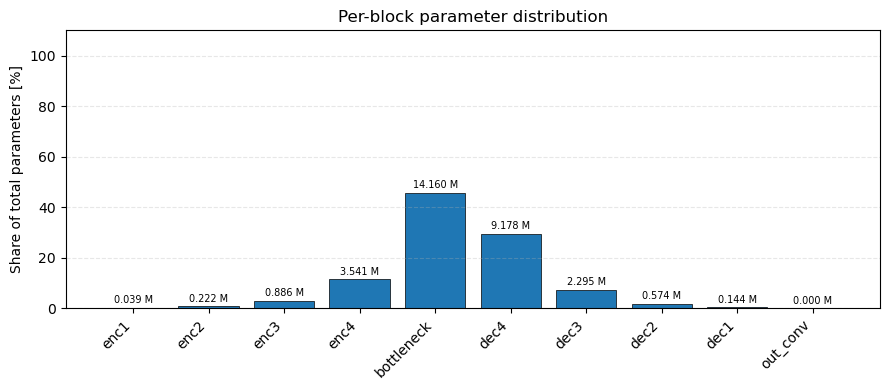

In [34]:
def plot_params_per_block(df_blocks: pd.DataFrame, figsize=(9, 4)):
    blocks = df_blocks["block"].values
    vals_M = df_blocks["params_M"].values
    perc = df_blocks["share_percent"].values

    x = np.arange(len(blocks))

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.bar(x, perc, edgecolor="black", linewidth=0.5)

    # Label: absolute params in M, on top of each bar
    for i, bar in enumerate(bars):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{vals_M[i]:.3f} M",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(blocks, rotation=45, ha="right")
    ax.set_ylabel("Share of total parameters [%]")
    ax.set_ylim(0, max(110, perc.max() + 10))
    ax.set_title("Per-block parameter distribution")

    ax.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_params_per_block(df_params_blocks)


#### macro (encoder / bottleneck / decoder) summary + plot

In [35]:
encoder_blocks   = ["enc1", "enc2", "enc3", "enc4"]
bottleneck_block = ["bottleneck"]
decoder_blocks   = ["dec4", "dec3", "dec2", "dec1", "out_conv"]


def sum_params(block_list, params_dict):
    return sum(params_dict[b] for b in block_list)


macro_rows = [
    {"section": "Encoder",   "params": sum_params(encoder_blocks, params_per_block_dict)},
    {"section": "Bottleneck","params": sum_params(bottleneck_block, params_per_block_dict)},
    {"section": "Decoder",   "params": sum_params(decoder_blocks, params_per_block_dict)},
]

df_params_macro = pd.DataFrame(macro_rows)
df_params_macro["params_M"] = df_params_macro["params"] / 1e6

total_params_macro = df_params_macro["params"].sum()
df_params_macro["share_percent"] = 100.0 * df_params_macro["params"] / (total_params_macro + 1e-12)

df_params_macro


,section,params,params_M,share_percent
0,Encoder,4687296,4.687296,15.101945
1,Bottleneck,14159872,14.159872,45.621528
2,Decoder,12190530,12.190530,39.276528


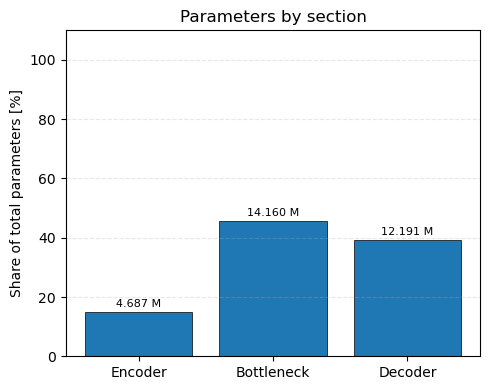

In [36]:
def plot_params_macro(df_macro: pd.DataFrame, figsize=(5, 4)):
    sections = df_macro["section"].values
    vals_M   = df_macro["params_M"].values
    perc     = df_macro["share_percent"].values

    x = np.arange(len(sections))

    fig, ax = plt.subplots(figsize=figsize)

    bars = ax.bar(x, perc, edgecolor="black", linewidth=0.5)

    # Labels: absolute params in M
    for i, bar in enumerate(bars):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{vals_M[i]:.3f} M",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(sections)
    ax.set_ylabel("Share of total parameters [%]")
    ax.set_ylim(0, max(110, perc.max() + 10))
    ax.set_title("Parameters by section")

    ax.grid(axis="y", linestyle="--", alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_params_macro(df_params_macro)


## Part 3: Per-block profiling for Brain U-Net (baseline size)

#### Profiling configuration (central place to change things)

In [37]:
import time
import torch
import torch.nn as nn

# ===== Profiling configuration =====
PROFILE_INPUT_SIZE = (1, 3, 128, 128)  # (N, C, H, W)
N_WARMUP_GPU = 5
N_RUNS_GPU   = 100

N_WARMUP_CPU = 5
N_RUNS_CPU   = 100

DEVICE_GPU = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE_CPU = torch.device("cpu")

print("Profiling config:")
print("  INPUT_SIZE :", PROFILE_INPUT_SIZE)
print("  GPU device :", DEVICE_GPU)
print("  CPU device :", DEVICE_CPU)
print("  GPU runs   :", N_RUNS_GPU)
print("  CPU runs   :", N_RUNS_CPU)


Profiling config:
  INPUT_SIZE : (1, 3, 128, 128)
  GPU device : cuda
  CPU device : cpu
  GPU runs   : 100
  CPU runs   : 100


#### Per-block timing (milesial UNet: inc/down/up/outc)

In [38]:
def profile_unet_blocks_time_milesial(
    model: nn.Module,
    input_size=(1, 3, 128, 128),
    device=None,
    n_warmup: int = 5,
    n_runs: int = 50,
):
    """
    Per-block average forward time for milesial/Pytorch-UNet:
    blocks = enc1..enc4, bottleneck, dec4..dec1, out_conv.

    Returns:
        times_ms: dict {block_name -> avg time in ms}
    """
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = model.to(device)
    model.eval()

    times_ms = {
        "enc1": 0.0,
        "enc2": 0.0,
        "enc3": 0.0,
        "enc4": 0.0,
        "bottleneck": 0.0,
        "dec4": 0.0,
        "dec3": 0.0,
        "dec2": 0.0,
        "dec1": 0.0,
        "out_conv": 0.0,
    }

    def sync():
        if device.type == "cuda":
            torch.cuda.synchronize()

    with torch.no_grad():
        x = torch.randn(*input_size, device=device)

        # Warmup full forward
        for _ in range(n_warmup):
            _ = model(x)
        sync()

        # Profiling runs
        for _ in range(n_runs):
            # ----- Encoder -----
            t0 = time.perf_counter()
            x1 = model.inc(x)        # enc1
            sync()
            t1 = time.perf_counter()
            times_ms["enc1"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            x2 = model.down1(x1)     # enc2
            sync()
            t1 = time.perf_counter()
            times_ms["enc2"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            x3 = model.down2(x2)     # enc3
            sync()
            t1 = time.perf_counter()
            times_ms["enc3"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            x4 = model.down3(x3)     # enc4
            sync()
            t1 = time.perf_counter()
            times_ms["enc4"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            x5 = model.down4(x4)     # bottleneck
            sync()
            t1 = time.perf_counter()
            times_ms["bottleneck"] += (t1 - t0) * 1000.0

            # ----- Decoder (Up blocks already include upsample + DoubleConv) -----
            t0 = time.perf_counter()
            y4 = model.up1(x5, x4)   # dec4
            sync()
            t1 = time.perf_counter()
            times_ms["dec4"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            y3 = model.up2(y4, x3)   # dec3
            sync()
            t1 = time.perf_counter()
            times_ms["dec3"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            y2 = model.up3(y3, x2)   # dec2
            sync()
            t1 = time.perf_counter()
            times_ms["dec2"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            y1 = model.up4(y2, x1)   # dec1
            sync()
            t1 = time.perf_counter()
            times_ms["dec1"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            out = model.outc(y1)     # out_conv
            sync()
            t1 = time.perf_counter()
            times_ms["out_conv"] += (t1 - t0) * 1000.0

        # Average over runs
        for k in times_ms:
            times_ms[k] /= n_runs

    return times_ms


# Run timing on GPU and CPU
times_blocks_gpu = profile_unet_blocks_time_milesial(
    model,
    input_size=PROFILE_INPUT_SIZE,
    device=DEVICE_GPU,
    n_warmup=N_WARMUP_GPU,
    n_runs=N_RUNS_GPU,
)

times_blocks_cpu = profile_unet_blocks_time_milesial(
    model,
    input_size=PROFILE_INPUT_SIZE,
    device=DEVICE_CPU,
    n_warmup=N_WARMUP_CPU,
    n_runs=N_RUNS_CPU,
)

print("Per-block avg forward time (ms) – GPU:")
for b in ["enc1", "enc2", "enc3", "enc4", "bottleneck",
          "dec4", "dec3", "dec2", "dec1", "out_conv"]:
    print(f"{b:11s}: {times_blocks_gpu[b]:.4f} ms")

print("\nPer-block avg forward time (ms) – CPU:")
for b in ["enc1", "enc2", "enc3", "enc4", "bottleneck",
          "dec4", "dec3", "dec2", "dec1", "out_conv"]:
    print(f"{b:11s}: {times_blocks_cpu[b]:.4f} ms")


Per-block avg forward time (ms) – GPU:
enc1       : 0.2100 ms
enc2       : 0.2030 ms
enc3       : 0.2039 ms
enc4       : 0.3677 ms
bottleneck : 0.8350 ms
dec4       : 0.8233 ms
dec3       : 0.3901 ms
dec2       : 0.3270 ms
dec1       : 0.4915 ms
out_conv   : 0.1126 ms

Per-block avg forward time (ms) – CPU:
enc1       : 1.0181 ms
enc2       : 1.1986 ms
enc3       : 5.9481 ms
enc4       : 3.6442 ms
bottleneck : 11.1956 ms
dec4       : 9.8489 ms
dec3       : 5.8686 ms
dec2       : 4.7001 ms
dec1       : 5.7035 ms
out_conv   : 0.9508 ms


#### FLOPs per block (milesial UNet)

In [39]:
def conv2d_flops(conv: nn.Conv2d, h: int, w: int) -> int:
    """
    FLOPs for Conv2d (multiply+add counted as 2 ops).
    """
    out_channels = conv.out_channels
    in_channels = conv.in_channels
    k_h, k_w = conv.kernel_size
    groups = conv.groups

    flops_per_out = 2 * (in_channels // groups) * k_h * k_w
    out_elems = out_channels * h * w
    return flops_per_out * out_elems


def convtranspose2d_flops(conv_t: nn.ConvTranspose2d, h: int, w: int) -> int:
    """
    FLOPs for ConvTranspose2d (same MAC counting).
    h, w are output spatial dimensions.
    """
    out_channels = conv_t.out_channels
    in_channels = conv_t.in_channels
    k_h, k_w = conv_t.kernel_size
    groups = conv_t.groups

    flops_per_out = 2 * (in_channels // groups) * k_h * k_w
    out_elems = out_channels * h * w
    return flops_per_out * out_elems


def compute_flops_per_block_milesial(model: nn.Module, shapes: dict) -> dict:
    """
    FLOPs per logical block (enc1..dec1, out_conv) for milesial UNet.
    Uses shapes from inspect_unet_blocks_milesial.
    """
    flops_block = {
        "enc1": 0,
        "enc2": 0,
        "enc3": 0,
        "enc4": 0,
        "bottleneck": 0,
        "dec4": 0,
        "dec3": 0,
        "dec2": 0,
        "dec1": 0,
        "out_conv": 0,
    }

    # Encoder blocks: inc, down1..3
    for name, module_name in zip(
        ["enc1", "enc2", "enc3", "enc4"],
        ["inc", "down1", "down2", "down3"],
    ):
        h, w = shapes[name][2], shapes[name][3]
        block = getattr(model, module_name)
        for m in block.modules():
            if isinstance(m, nn.Conv2d):
                flops_block[name] += conv2d_flops(m, h, w)
            elif isinstance(m, nn.ConvTranspose2d):
                flops_block[name] += convtranspose2d_flops(m, h, w)

    # Bottleneck: down4
    h, w = shapes["bottleneck"][2], shapes["bottleneck"][3]
    for m in model.down4.modules():
        if isinstance(m, nn.Conv2d):
            flops_block["bottleneck"] += conv2d_flops(m, h, w)
        elif isinstance(m, nn.ConvTranspose2d):
            flops_block["bottleneck"] += convtranspose2d_flops(m, h, w)

    # Decoder blocks: up1..4 (each includes upsample + DoubleConv)
    for name, module_name in zip(
        ["dec4", "dec3", "dec2", "dec1"],
        ["up1", "up2", "up3", "up4"],
    ):
        h, w = shapes[name][2], shapes[name][3]
        block = getattr(model, module_name)
        for m in block.modules():
            if isinstance(m, nn.Conv2d):
                flops_block[name] += conv2d_flops(m, h, w)
            elif isinstance(m, nn.ConvTranspose2d):
                flops_block[name] += convtranspose2d_flops(m, h, w)

    # Final 1×1 conv: outc
    h, w = shapes["out"][2], shapes["out"][3]
    for m in model.outc.modules():
        if isinstance(m, nn.Conv2d):
            flops_block["out_conv"] += conv2d_flops(m, h, w)
        elif isinstance(m, nn.ConvTranspose2d):
            flops_block["out_conv"] += convtranspose2d_flops(m, h, w)

    return flops_block


# Shapes for the profiling input size
shapes_profile = inspect_unet_blocks_milesial(
    model, input_size=PROFILE_INPUT_SIZE, device=DEVICE_GPU
)

flops_blocks = compute_flops_per_block_milesial(model, shapes_profile)

print("Per-block FLOPs for input", PROFILE_INPUT_SIZE, "(MACs counted as FLOPs):")
for b in ["enc1", "enc2", "enc3", "enc4", "bottleneck",
          "dec4", "dec3", "dec2", "dec1", "out_conv"]:
    print(f"{b:11s}: {flops_blocks[b] / 1e6:.3f} MFLOPs")

print(f"\nTotal FLOPs: {sum(flops_blocks.values()) / 1e6:.3f} MFLOPs")
# Remark: MFLOPs = Mega-FLOPs = 1 million FLOPs


Per-block FLOPs for input (1, 3, 128, 128) (MACs counted as FLOPs):
enc1       : 1264.583 MFLOPs
enc2       : 1811.939 MFLOPs
enc3       : 1811.939 MFLOPs
enc4       : 1811.939 MFLOPs
bottleneck : 1811.939 MFLOPs
dec4       : 4697.620 MFLOPs
dec3       : 4697.620 MFLOPs
dec2       : 4697.620 MFLOPs
dec1       : 4697.620 MFLOPs
out_conv   : 4.194 MFLOPs

Total FLOPs: 27307.016 MFLOPs


#### Build per-block DataFrame (time + FLOPs, with shares)

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

blocks_order = ["enc1", "enc2", "enc3", "enc4",
                "bottleneck",
                "dec4", "dec3", "dec2", "dec1", "out_conv"]

rows = []
for b in blocks_order:
    t_gpu = times_blocks_gpu[b]
    t_cpu = times_blocks_cpu[b]
    fl   = flops_blocks[b]
    rows.append({
        "block": b,
        "time_gpu_ms": t_gpu,
        "time_cpu_ms": t_cpu,
        "flops_M": fl / 1e6,
    })

df_time_flops_blocks = pd.DataFrame(rows)

# Total times and FLOPs
total_gpu_time = df_time_flops_blocks["time_gpu_ms"].sum()
total_cpu_time = df_time_flops_blocks["time_cpu_ms"].sum()
total_flops_M  = df_time_flops_blocks["flops_M"].sum()

# Shares in %
df_time_flops_blocks["share_gpu_time_percent"] = (
    100.0 * df_time_flops_blocks["time_gpu_ms"] / (total_gpu_time + 1e-12)
)
df_time_flops_blocks["share_cpu_time_percent"] = (
    100.0 * df_time_flops_blocks["time_cpu_ms"] / (total_cpu_time + 1e-12)
)
df_time_flops_blocks["share_flops_percent"] = (
    100.0 * df_time_flops_blocks["flops_M"] / (total_flops_M + 1e-12)
)

df_time_flops_blocks


,block,time_gpu_ms,time_cpu_ms,flops_M,share_gpu_time_percent,share_cpu_time_percent,share_flops_percent
0,enc1,0.209962,1.018110,1264.582656,5.296429,2.033111,4.630981
1,enc2,0.202976,1.198596,1811.939328,5.120216,2.393532,6.635435
2,enc3,0.203924,5.948135,1811.939328,5.144120,11.878104,6.635435
3,enc4,0.367710,3.644158,1811.939328,9.275753,7.277186,6.635435
4,bottleneck,0.835034,11.195588,1811.939328,21.064325,22.356987,6.635435
5,dec4,0.823332,9.848887,4697.620480,20.769126,19.667696,17.202980
6,dec3,0.390138,5.868564,4697.620480,9.841508,11.719206,17.202980
7,dec2,0.326996,4.700121,4697.620480,8.248706,9.385889,17.202980
8,dec1,0.491534,5.703514,4697.620480,12.399302,11.389611,17.202980
9,out_conv,0.112604,0.950791,4.194304,2.840515,1.898679,0.015360


#### Plots: per-block time distribution (GPU & CPU) + per-block FLOPs

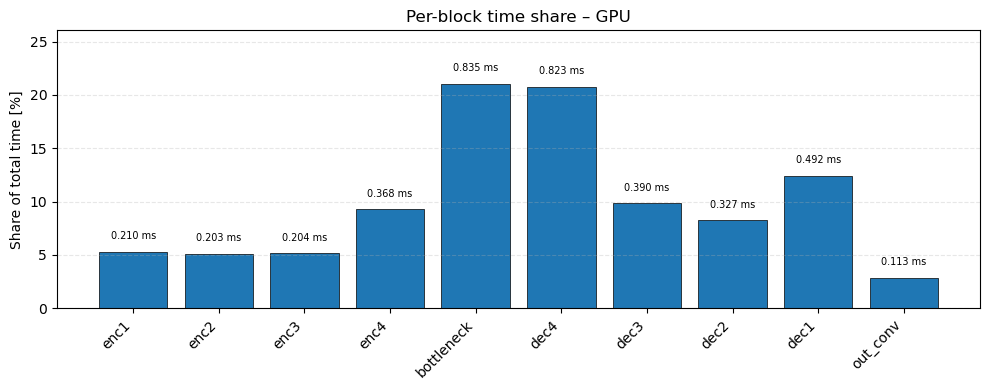

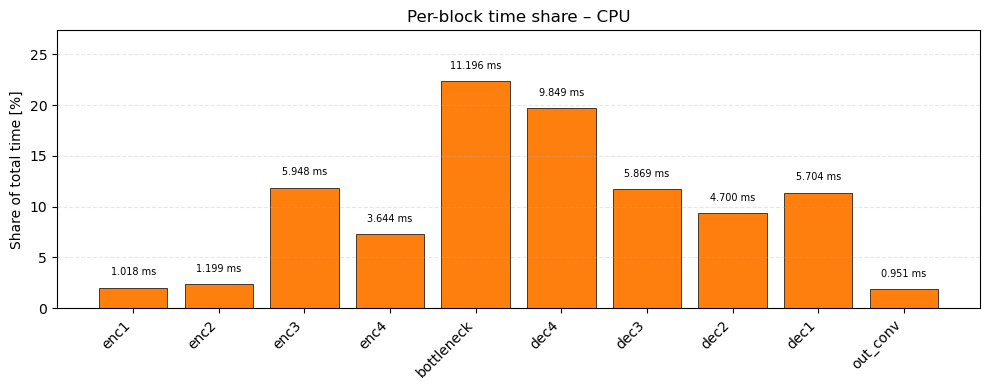

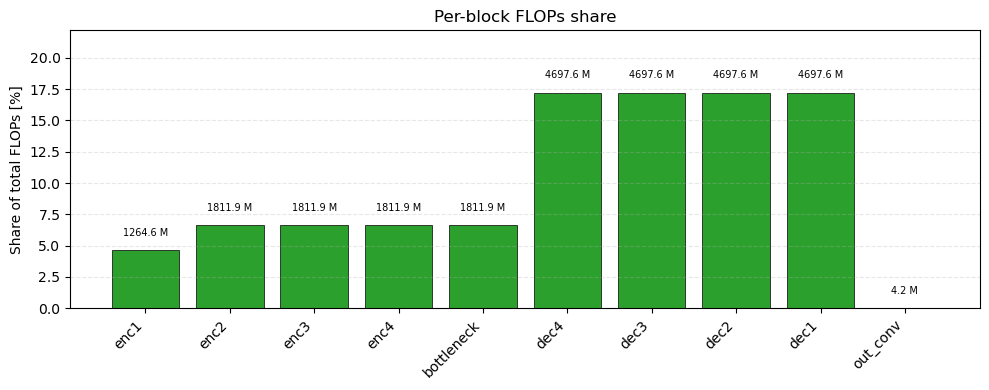

In [41]:
def plot_time_share_blocks(df, device: str = "gpu", figsize=(10, 4)):
    """
    device: "gpu" or "cpu"
    """
    blocks = df["block"].values

    if device == "gpu":
        shares = df["share_gpu_time_percent"].values
        times  = df["time_gpu_ms"].values
        title  = "Per-block time share – GPU"
        color  = "tab:blue"
    else:
        shares = df["share_cpu_time_percent"].values
        times  = df["time_cpu_ms"].values
        title  = "Per-block time share – CPU"
        color  = "tab:orange"

    x = np.arange(len(blocks))

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(x, shares, color=color, edgecolor="black", linewidth=0.5)

    for i, bar in enumerate(bars):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{times[i]:.3f} ms",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(blocks, rotation=45, ha="right")
    ax.set_ylabel("Share of total time [%]")
    ax.set_ylim(0, shares.max() + 5)
    ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_flops_share_blocks(df, figsize=(10, 4)):
    blocks = df["block"].values
    flops_M = df["flops_M"].values
    shares  = df["share_flops_percent"].values

    x = np.arange(len(blocks))

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(x, shares, color="tab:green", edgecolor="black", linewidth=0.5)

    for i, bar in enumerate(bars):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{flops_M[i]:.1f} M",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(blocks, rotation=45, ha="right")
    ax.set_ylabel("Share of total FLOPs [%]")
    ax.set_ylim(0, shares.max() + 5)
    ax.set_title("Per-block FLOPs share")
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


# Time distribution over blocks
plot_time_share_blocks(df_time_flops_blocks, device="gpu")
plot_time_share_blocks(df_time_flops_blocks, device="cpu")

# FLOPs distribution over blocks
plot_flops_share_blocks(df_time_flops_blocks)


#### Macro (Encoder / Bottleneck / Decoder): time + FLOPs, text + plots

In [42]:
encoder_blocks   = ["enc1", "enc2", "enc3", "enc4"]
bottleneck_block = ["bottleneck"]
decoder_blocks   = ["dec4", "dec3", "dec2", "dec1", "out_conv"]

def sum_over(blocks, d):
    return sum(d[b] for b in blocks)

# Aggregate times and FLOPs by macro-section
macro_rows = [
    {
        "section": "Encoder",
        "time_gpu_ms": sum_over(encoder_blocks, times_blocks_gpu),
        "time_cpu_ms": sum_over(encoder_blocks, times_blocks_cpu),
        "flops_M": sum_over(encoder_blocks, flops_blocks) / 1e6,
    },
    {
        "section": "Bottleneck",
        "time_gpu_ms": sum_over(bottleneck_block, times_blocks_gpu),
        "time_cpu_ms": sum_over(bottleneck_block, times_blocks_cpu),
        "flops_M": sum_over(bottleneck_block, flops_blocks) / 1e6,
    },
    {
        "section": "Decoder",
        "time_gpu_ms": sum_over(decoder_blocks, times_blocks_gpu),
        "time_cpu_ms": sum_over(decoder_blocks, times_blocks_cpu),
        "flops_M": sum_over(decoder_blocks, flops_blocks) / 1e6,
    },
]

df_macro = pd.DataFrame(macro_rows)

# Shares
total_gpu_macro = df_macro["time_gpu_ms"].sum()
total_cpu_macro = df_macro["time_cpu_ms"].sum()
total_flops_macro_M = df_macro["flops_M"].sum()

df_macro["share_gpu_time_percent"] = (
100.0 * df_macro["time_gpu_ms"] / (total_gpu_macro + 1e-12)
)
df_macro["share_cpu_time_percent"] = (
    100.0 * df_macro["time_cpu_ms"] / (total_cpu_macro + 1e-12)
)
df_macro["share_flops_percent"] = (
    100.0 * df_macro["flops_M"] / (total_flops_macro_M + 1e-12)
)

df_macro


,section,time_gpu_ms,time_cpu_ms,flops_M,share_gpu_time_percent,share_cpu_time_percent,share_flops_percent
0,Encoder,0.984572,11.808998,6700.400640,24.836518,23.581933,24.537286
1,Bottleneck,0.835034,11.195588,1811.939328,21.064325,22.356987,6.635435
2,Decoder,2.144605,27.071878,18794.676224,54.099157,54.061080,68.827279


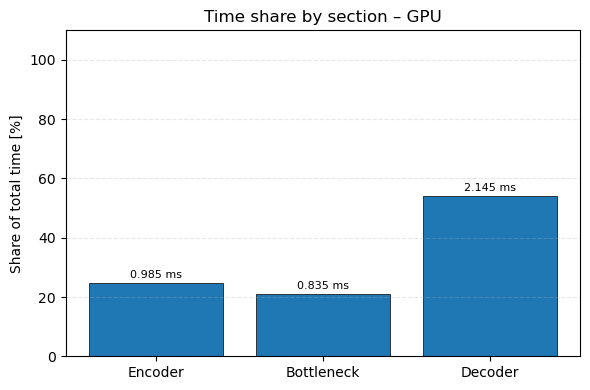

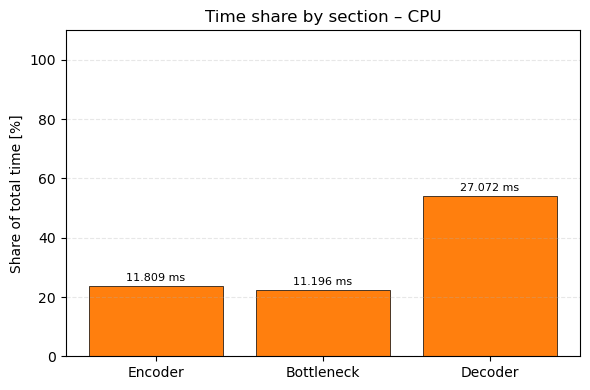

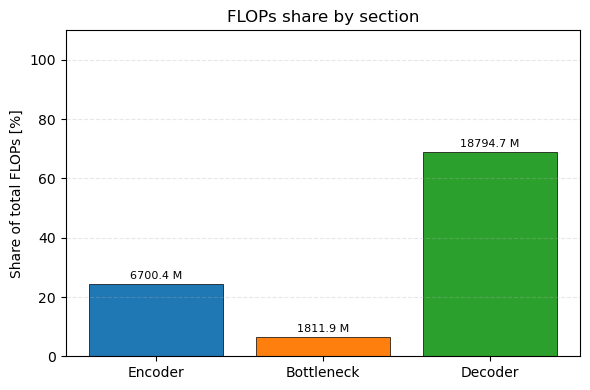

In [43]:
def plot_macro_time(df_macro, device: str = "gpu", figsize=(6, 4)):
    sections = df_macro["section"].values
    if device == "gpu":
        shares = df_macro["share_gpu_time_percent"].values
        times  = df_macro["time_gpu_ms"].values
        title  = "Time share by section – GPU"
        color  = "tab:blue"
    else:
        shares = df_macro["share_cpu_time_percent"].values
        times  = df_macro["time_cpu_ms"].values
        title  = "Time share by section – CPU"
        color  = "tab:orange"

    x = np.arange(len(sections))

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(x, shares, color=color, edgecolor="black", linewidth=0.5)

    for i, bar in enumerate(bars):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{times[i]:.3f} ms",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(sections)
    ax.set_ylabel("Share of total time [%]")
    ax.set_ylim(0, max(110, shares.max() + 10))
    ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


def plot_macro_flops(df_macro, figsize=(6, 4)):
    sections = df_macro["section"].values
    flops_M  = df_macro["flops_M"].values
    shares   = df_macro["share_flops_percent"].values

    x = np.arange(len(sections))

    fig, ax = plt.subplots(figsize=figsize)
    bars = ax.bar(
        x,
        shares,
        color=["tab:blue", "tab:orange", "tab:green"],
        edgecolor="black",
        linewidth=0.5,
    )

    for i, bar in enumerate(bars):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{flops_M[i]:.1f} M",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(sections)
    ax.set_ylabel("Share of total FLOPs [%]")
    ax.set_ylim(0, max(110, shares.max() + 10))
    ax.set_title("FLOPs share by section")
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


# Time distribution by Encoder / Bottleneck / Decoder
plot_macro_time(df_macro, device="gpu")
plot_macro_time(df_macro, device="cpu")

# FLOPs distribution by Encoder / Bottleneck / Decoder
plot_macro_flops(df_macro)


## Part 4: Input-size scaling (add 1024×1024)

#### Config + helpers for size-scaling

In [44]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =======================================================
# Input-size scaling configuration
# =======================================================
SIZES = [128, 256, 512, 1024]   # input is (1, 3, S, S)

N_WARMUP_SIZE = 5
N_RUNS_GPU_SIZE = 100    # adjust if too slow for 1024
N_RUNS_CPU_SIZE = 100

print("Size-scaling config:")
print("  SIZES         :", SIZES)
print("  GPU runs      :", N_RUNS_GPU_SIZE)
print("  CPU runs      :", N_RUNS_CPU_SIZE)
print("  Warmup steps  :", N_WARMUP_SIZE)


# =======================================================
# Helper: summarize encoder / bottleneck / decoder
# =======================================================
def summarize_encoder_bottleneck_decoder(
    times_ms: dict,
    flops_block: dict,
    params_per_block: dict,
    encoder_blocks,
    bottleneck_block,
    decoder_blocks,
):
    def s(blocks, d):
        return sum(d[b] for b in blocks)

    summary = {}

    # Time
    summary["time_encoder_ms"] = s(encoder_blocks, times_ms)
    summary["time_bottleneck_ms"] = s(bottleneck_block, times_ms)
    summary["time_decoder_ms"] = s(decoder_blocks, times_ms)
    summary["time_total_ms"] = sum(times_ms.values())

    # Params (independent of input size)
    summary["params_encoder"] = s(encoder_blocks, params_per_block)
    summary["params_bottleneck"] = s(bottleneck_block, params_per_block)
    summary["params_decoder"] = s(decoder_blocks, params_per_block)
    summary["params_total"] = sum(params_per_block.values())

    # FLOPs
    summary["flops_encoder"] = s(encoder_blocks, flops_block)
    summary["flops_bottleneck"] = s(bottleneck_block, flops_block)
    summary["flops_decoder"] = s(decoder_blocks, flops_block)
    summary["flops_total"] = sum(flops_block.values())

    return summary


# =======================================================
# Helper: profile model for a given input size and device
# =======================================================
def profile_for_size(
    model,
    size: int,
    device: torch.device,
    n_runs: int,
    n_warmup: int,
    params_per_block: dict,
    encoder_blocks,
    bottleneck_block,
    decoder_blocks,
):
    """
    size: scalar, input = (1, 3, size, size)
    Returns:
        - summary: dict with encoder/bottleneck/decoder + totals (time, FLOPs, params)
        - flops_block: dict FLOPs per block
    """
    input_size = (1, 3, size, size)
    print(f"\n=== Profiling for input size {input_size} on {device} ===")

    # 1) Shapes (one forward)
    shapes = inspect_unet_blocks_milesial(model, input_size=input_size, device=device)

    # 2) FLOPs per block (analytic)
    flops_block = compute_flops_per_block_milesial(model, shapes)

    # 3) Time per block (empirical, n_runs fixed across sizes)
    times_ms = profile_unet_blocks_time_milesial(
        model,
        input_size=input_size,
        device=device,
        n_warmup=n_warmup,
        n_runs=n_runs,
    )

    # 4) Aggregate encoder / bottleneck / decoder
    summary = summarize_encoder_bottleneck_decoder(
        times_ms,
        flops_block,
        params_per_block,
        encoder_blocks,
        bottleneck_block,
        decoder_blocks,
    )

    print(f"  Total time  : {summary['time_total_ms']:.3f} ms")
    print(f"  Total FLOPs : {summary['flops_total'] / 1e6:.3f} MFLOPs")

    return summary, flops_block


Size-scaling config:
  SIZES         : [128, 256, 512, 1024]
  GPU runs      : 100
  CPU runs      : 100
  Warmup steps  : 5


#### Run profiling for all sizes (GPU + CPU) and build summary table

In [45]:
# Dictionaries: size -> summary / flops
gpu_results_by_size = {}
cpu_results_by_size = {}
flops_by_size = {}   # FLOPs do not depend on device

# ---- GPU ----
print("\n===== Profiling on GPU =====")
for sz in SIZES:
    summ, fl = profile_for_size(
        model,
        size=sz,
        device=DEVICE_GPU,
        n_runs=N_RUNS_GPU_SIZE,
        n_warmup=N_WARMUP_SIZE,
        params_per_block=params_per_block_dict,
        encoder_blocks=encoder_blocks,
        bottleneck_block=bottleneck_block,
        decoder_blocks=decoder_blocks,
    )
    gpu_results_by_size[sz] = summ
    flops_by_size[sz] = fl

# ---- CPU ----
print("\n===== Profiling on CPU =====")
for sz in SIZES:
    summ, _ = profile_for_size(
        model,
        size=sz,
        device=DEVICE_CPU,
        n_runs=N_RUNS_CPU_SIZE,
        n_warmup=N_WARMUP_SIZE,
        params_per_block=params_per_block_dict,
        encoder_blocks=encoder_blocks,
        bottleneck_block=bottleneck_block,
        decoder_blocks=decoder_blocks,
    )
    cpu_results_by_size[sz] = summ


# =======================================================
# Build a compact DataFrame summarizing per size
# =======================================================
rows = []
for sz in SIZES:
    gpu_s = gpu_results_by_size[sz]
    cpu_s = cpu_results_by_size[sz]

    rows.append({
        "size": sz,

        # GPU times
        "gpu_time_total_ms": gpu_s["time_total_ms"],
        "gpu_time_encoder_ms": gpu_s["time_encoder_ms"],
        "gpu_time_bottleneck_ms": gpu_s["time_bottleneck_ms"],
        "gpu_time_decoder_ms": gpu_s["time_decoder_ms"],

        # CPU times
        "cpu_time_total_ms": cpu_s["time_total_ms"],
        "cpu_time_encoder_ms": cpu_s["time_encoder_ms"],
        "cpu_time_bottleneck_ms": cpu_s["time_bottleneck_ms"],
        "cpu_time_decoder_ms": cpu_s["time_decoder_ms"],

        # FLOPs (M)
        "flops_total_M":        gpu_s["flops_total"] / 1e6,
        "flops_encoder_M":      gpu_s["flops_encoder"] / 1e6,
        "flops_bottleneck_M":   gpu_s["flops_bottleneck"] / 1e6,
        "flops_decoder_M":      gpu_s["flops_decoder"] / 1e6,

        # Params (M) — constant across sizes, but kept for completeness
        "params_total_M":       gpu_s["params_total"] / 1e6,
        "params_encoder_M":     gpu_s["params_encoder"] / 1e6,
        "params_bottleneck_M":  gpu_s["params_bottleneck"] / 1e6,
        "params_decoder_M":     gpu_s["params_decoder"] / 1e6,
    })

df_sizes = pd.DataFrame(rows).sort_values("size").reset_index(drop=True)
df_sizes



===== Profiling on GPU =====

=== Profiling for input size (1, 3, 128, 128) on cuda ===
  Total time  : 4.001 ms
  Total FLOPs : 27307.016 MFLOPs

=== Profiling for input size (1, 3, 256, 256) on cuda ===
  Total time  : 7.905 ms
  Total FLOPs : 109228.065 MFLOPs

=== Profiling for input size (1, 3, 512, 512) on cuda ===
  Total time  : 23.364 ms
  Total FLOPs : 436912.259 MFLOPs

=== Profiling for input size (1, 3, 1024, 1024) on cuda ===
  Total time  : 86.915 ms
  Total FLOPs : 1747649.036 MFLOPs

===== Profiling on CPU =====

=== Profiling for input size (1, 3, 128, 128) on cpu ===
  Total time  : 57.755 ms
  Total FLOPs : 27307.016 MFLOPs

=== Profiling for input size (1, 3, 256, 256) on cpu ===
  Total time  : 113.868 ms
  Total FLOPs : 109228.065 MFLOPs

=== Profiling for input size (1, 3, 512, 512) on cpu ===
  Total time  : 678.070 ms
  Total FLOPs : 436912.259 MFLOPs

=== Profiling for input size (1, 3, 1024, 1024) on cpu ===
  Total time  : 3524.894 ms
  Total FLOPs : 17476

,size,gpu_time_total_ms,gpu_time_encoder_ms,gpu_time_bottleneck_ms,gpu_time_decoder_ms,cpu_time_total_ms,cpu_time_encoder_ms,cpu_time_bottleneck_ms,cpu_time_decoder_ms,flops_total_M,flops_encoder_M,flops_bottleneck_M,flops_decoder_M,params_total_M,params_encoder_M,params_bottleneck_M,params_decoder_M
0,128,4.001305,0.989073,0.873535,2.138697,57.754756,12.111512,12.439888,33.203356,2.730702e+04,6700.40064,1811.939328,1.879468e+04,31.037698,4.687296,14.159872,12.19053
1,256,7.905358,2.175263,1.117654,4.612442,113.867578,31.702719,9.136010,73.028849,1.092281e+05,26801.60256,7247.757312,7.517870e+04,31.037698,4.687296,14.159872,12.19053
2,512,23.363627,7.241847,1.363483,14.758297,678.070046,197.859431,23.325397,456.885217,4.369123e+05,107206.41024,28991.029248,3.007148e+05,31.037698,4.687296,14.159872,12.19053
3,1024,86.915213,27.732254,3.584074,55.598885,3524.893930,1137.110670,73.604823,2314.178436,1.747649e+06,428825.64096,115964.116992,1.202859e+06,31.037698,4.687296,14.159872,12.19053


#### Time vs input size: GPU, CPU, FLOPs

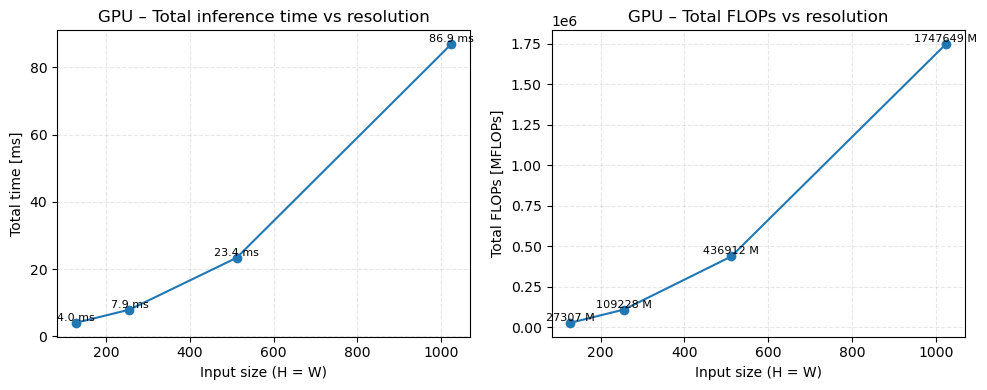

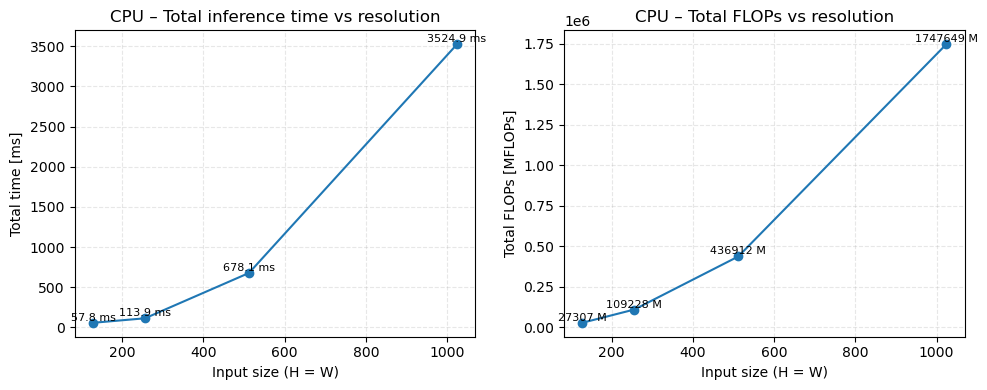

In [46]:
import matplotlib.pyplot as plt
import numpy as np

def plot_time_and_flops_vs_size(
    df_sizes,
    time_col: str,
    flops_col: str,
    figsize=(10, 4),
    title_prefix: str = "",
):
    """
    df_sizes must contain:
      - 'size'
      - time_col   (e.g. 'gpu_time_total_ms' or 'cpu_time_total_ms')
      - flops_col  (e.g. 'flops_total_M')
    """
    sizes = df_sizes["size"].values
    times = df_sizes[time_col].values      # ms
    flops = df_sizes[flops_col].values     # MFLOPs

    fig, axes = plt.subplots(1, 2, figsize=figsize)

    # --- Time vs size ---
    ax = axes[0]
    ax.plot(sizes, times, marker="o")
    for x, y in zip(sizes, times):
        ax.text(x, y, f"{y:.1f} ms", ha="center", va="bottom", fontsize=8)
    ax.set_xlabel("Input size (H = W)")
    ax.set_ylabel("Total time [ms]")
    ax.set_title(f"{title_prefix}Total inference time vs resolution")
    ax.grid(True, linestyle="--", alpha=0.3)

    # --- FLOPs vs size ---
    ax = axes[1]
    ax.plot(sizes, flops, marker="o")
    for x, y in zip(sizes, flops):
        ax.text(x, y, f"{y:.0f} M", ha="center", va="bottom", fontsize=8)
    ax.set_xlabel("Input size (H = W)")
    ax.set_ylabel("Total FLOPs [MFLOPs]")
    ax.set_title(f"{title_prefix}Total FLOPs vs resolution")
    ax.grid(True, linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


# GPU view
plot_time_and_flops_vs_size(
    df_sizes,
    time_col="gpu_time_total_ms",
    flops_col="flops_total_M",
    title_prefix="GPU – "
)

# CPU view (optional but useful)
plot_time_and_flops_vs_size(
    df_sizes,
    time_col="cpu_time_total_ms",
    flops_col="flops_total_M",
    title_prefix="CPU – "
)


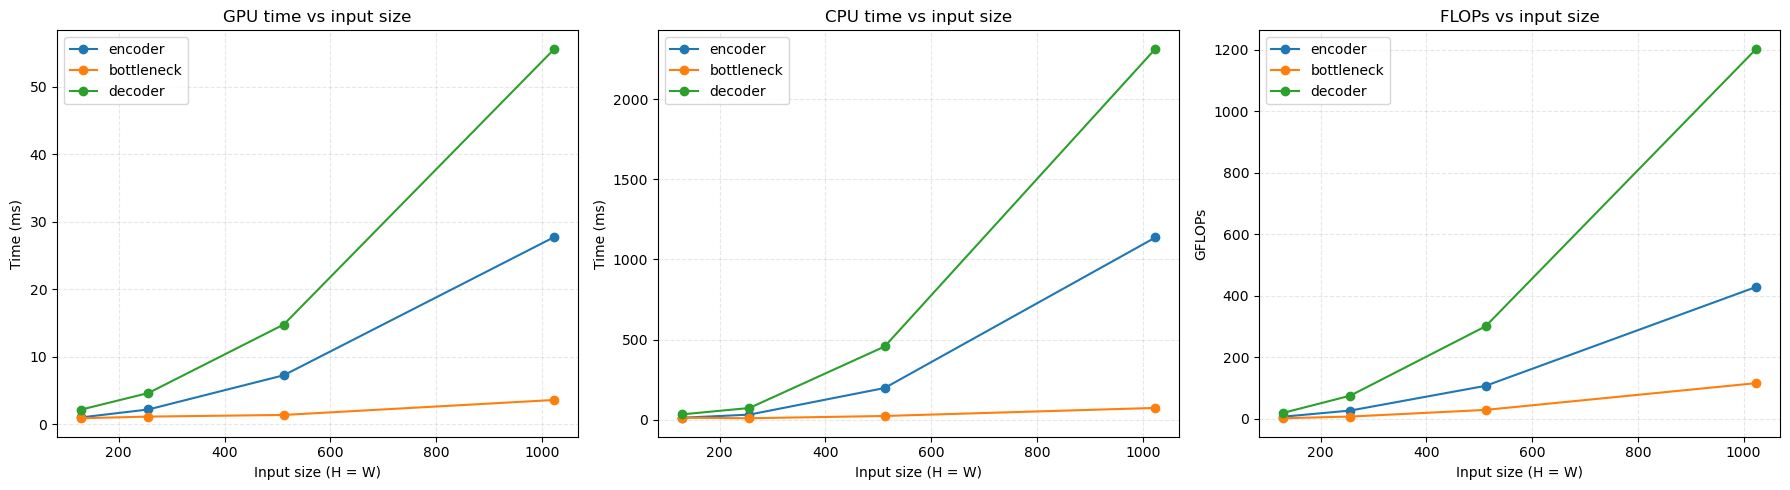

In [47]:
sizes = df_sizes["size"].values.astype(np.int32)

# GPU times
gpu_enc = df_sizes["gpu_time_encoder_ms"].values
gpu_bot = df_sizes["gpu_time_bottleneck_ms"].values
gpu_dec = df_sizes["gpu_time_decoder_ms"].values

# CPU times
cpu_enc = df_sizes["cpu_time_encoder_ms"].values
cpu_bot = df_sizes["cpu_time_bottleneck_ms"].values
cpu_dec = df_sizes["cpu_time_decoder_ms"].values

# FLOPs (GFLOPs)
fl_enc = df_sizes["flops_encoder_M"].values / 1e3
fl_bot = df_sizes["flops_bottleneck_M"].values / 1e3
fl_dec = df_sizes["flops_decoder_M"].values / 1e3

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# -------- GPU TIME --------
axes[0].plot(sizes, gpu_enc, "-o", label="encoder")
axes[0].plot(sizes, gpu_bot, "-o", label="bottleneck")
axes[0].plot(sizes, gpu_dec, "-o", label="decoder")
axes[0].set_title("GPU time vs input size")
axes[0].set_xlabel("Input size (H = W)")
axes[0].set_ylabel("Time (ms)")
axes[0].grid(True, linestyle="--", alpha=0.3)
axes[0].legend()

# -------- CPU TIME --------
axes[1].plot(sizes, cpu_enc, "-o", label="encoder")
axes[1].plot(sizes, cpu_bot, "-o", label="bottleneck")
axes[1].plot(sizes, cpu_dec, "-o", label="decoder")
axes[1].set_title("CPU time vs input size")
axes[1].set_xlabel("Input size (H = W)")
axes[1].set_ylabel("Time (ms)")
axes[1].grid(True, linestyle="--", alpha=0.3)
axes[1].legend()

# -------- FLOPs --------
axes[2].plot(sizes, fl_enc, "-o", label="encoder")
axes[2].plot(sizes, fl_bot, "-o", label="bottleneck")
axes[2].plot(sizes, fl_dec, "-o", label="decoder")
axes[2].set_title("FLOPs vs input size")
axes[2].set_xlabel("Input size (H = W)")
axes[2].set_ylabel("GFLOPs")
axes[2].grid(True, linestyle="--", alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()


#### Time share (Encoder / Bottleneck / Decoder) vs size (GPU)

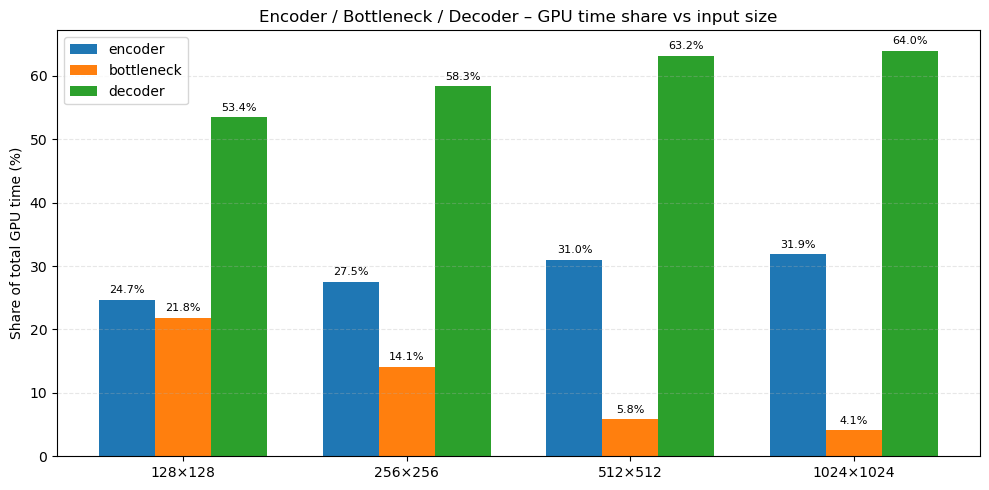

In [48]:
# Shares (GPU) of total time per size
tot_gpu = df_sizes["gpu_time_total_ms"].values

enc_share_gpu = df_sizes["gpu_time_encoder_ms"].values / (tot_gpu + 1e-12) * 100.0
bot_share_gpu = df_sizes["gpu_time_bottleneck_ms"].values / (tot_gpu + 1e-12) * 100.0
dec_share_gpu = df_sizes["gpu_time_decoder_ms"].values / (tot_gpu + 1e-12) * 100.0

x = np.arange(len(sizes))
width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(x - width, enc_share_gpu, width, label="encoder")
plt.bar(x,        bot_share_gpu, width, label="bottleneck")
plt.bar(x + width, dec_share_gpu, width, label="decoder")

for i, v in enumerate(enc_share_gpu):
    plt.text(i - width, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
for i, v in enumerate(bot_share_gpu):
    plt.text(i, v + 1, f"{v:.1f}%", ha="center", fontsize=8)
for i, v in enumerate(dec_share_gpu):
    plt.text(i + width, v + 1, f"{v:.1f}%", ha="center", fontsize=8)

plt.xticks(x, [f"{s}×{s}" for s in sizes])
plt.ylabel("Share of total GPU time (%)")
plt.title("Encoder / Bottleneck / Decoder – GPU time share vs input size")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


#### Helpers: breakdown + generic stacked plot

In [49]:
import numpy as np
import matplotlib.pyplot as plt

def breakdown_from_summary(summary: dict, metric: str = "time"):
    """
    summary: one entry from gpu_results_by_size[size] or cpu_results_by_size[size]
             (output of summarize_encoder_bottleneck_decoder)
    metric:  "time", "flops", or "params"

    Returns:
        abs_vals: [encoder, bottleneck, decoder] in chosen units
        percents: same, but in % of total
    """
    if metric == "time":
        keys = ["time_encoder_ms", "time_bottleneck_ms", "time_decoder_ms"]
        total_key = "time_total_ms"
        scale = 1.0  # ms
    elif metric == "flops":
        keys = ["flops_encoder", "flops_bottleneck", "flops_decoder"]
        total_key = "flops_total"
        scale = 1e-6  # convert to MFLOPs
    elif metric == "params":
        keys = ["params_encoder", "params_bottleneck", "params_decoder"]
        total_key = "params_total"
        scale = 1e-6  # convert to M params
    else:
        raise ValueError(f"Unknown metric: {metric}")

    raw_vals = np.array([summary[k] for k in keys], dtype=float)
    abs_vals = raw_vals * scale
    total = raw_vals.sum()  # same as summary[total_key]
    percents = 100.0 * raw_vals / (total + 1e-12)

    return abs_vals, percents


def plot_ebd_percent_by_size(
    results_by_size: dict,
    sizes,
    metric: str = "time",
    unit: str | None = None,
    figsize=(8, 5),
    title_prefix: str = "",
):
    """
    Stacked percent bars (Encoder/Bottleneck/Decoder) for several input sizes.

    results_by_size: dict {size -> summary_dict}
                     summary_dict comes from summarize_encoder_bottleneck_decoder(...)
    sizes:           iterable of sizes, e.g. [128, 256, 512, 1024]
    metric:          "time", "flops", or "params"
    unit:            if None:
                        time   -> "ms"
                        flops  -> "MFLOPs"
                        params -> "M params"
    """
    sizes = sorted(sizes)
    n = len(sizes)

    abs_vals_all = []   # shape (n, 3)
    perc_all = []       # shape (n, 3)

    for sz in sizes:
        summary = results_by_size[sz]
        vals, perc = breakdown_from_summary(summary, metric=metric)
        abs_vals_all.append(vals)
        perc_all.append(perc)

    abs_vals_all = np.stack(abs_vals_all, axis=0)  # (n, 3)
    perc_all = np.stack(perc_all, axis=0)          # (n, 3)

    labels_ebd = ["Encoder", "Bottleneck", "Decoder"]
    if unit is None:
        if metric == "time":
            unit = "ms"
        elif metric == "flops":
            unit = "MFLOPs"
        elif metric == "params":
            unit = "M params"

    indices = np.arange(n)
    bottom = np.zeros(n)
    colors = ["tab:blue", "tab:orange", "tab:green"]

    fig, ax = plt.subplots(figsize=figsize)

    for i in range(3):
        perc_i = perc_all[:, i]
        vals_i = abs_vals_all[:, i]

        bars = ax.bar(
            indices,
            perc_i,
            bottom=bottom,
            label=labels_ebd[i],
            color=colors[i],
            edgecolor="black",
            linewidth=0.5,
        )

        # Annotate with absolute value + unit for reasonably large segments
        for j, bar in enumerate(bars):
            if perc_i[j] < 5.0:  # skip tiny segments
                continue
            h = bar.get_height()
            y_pos = bar.get_y() + h / 2.0
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                y_pos,
                f"{vals_i[j]:.1f} {unit}",
                ha="center",
                va="center",
                fontsize=8,
                color="white",
            )

        bottom += perc_i

    ax.set_xticks(indices)
    ax.set_xticklabels([f"{s}×{s}" for s in sizes])
    ax.set_ylabel("Share [%]")
    ax.set_ylim(0, 100)

    title_metric = metric.capitalize()
    full_title = f"{title_prefix}{title_metric} breakdown by input size"
    ax.set_title(full_title.strip())

    ax.legend(loc="upper right", frameon=True)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


#### Use it on GPU results (time + FLOPs)

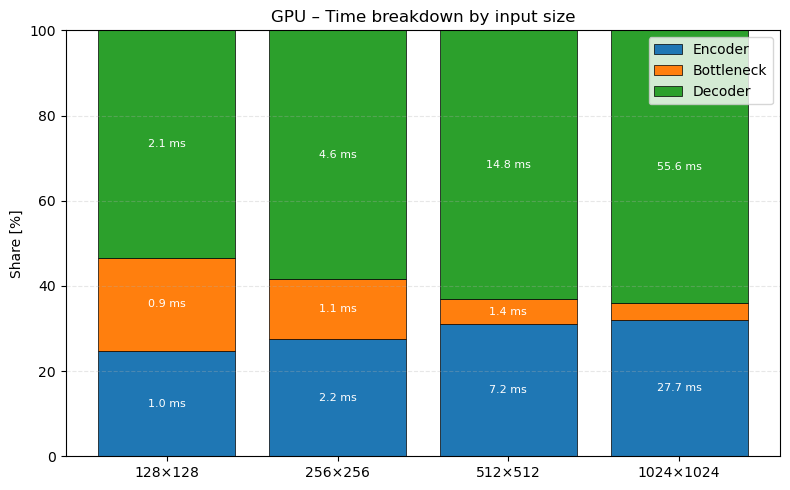

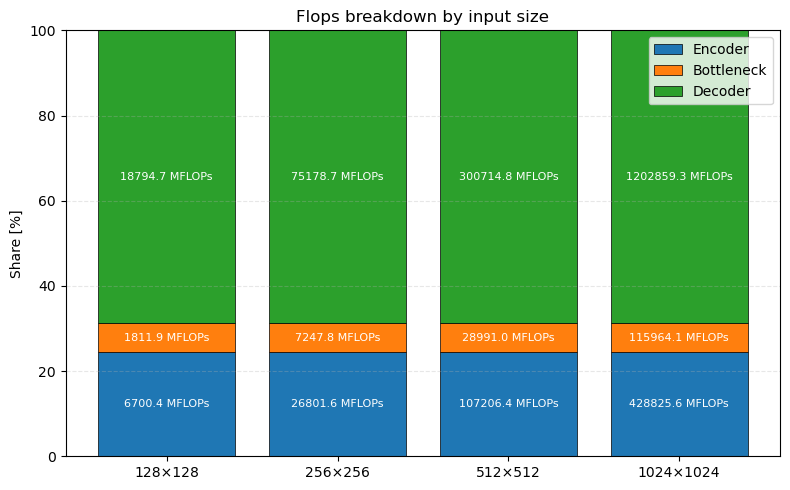

In [50]:
# Encoder/Bottleneck/Decoder time share vs input size (GPU)
plot_ebd_percent_by_size(
    results_by_size=gpu_results_by_size,   # dict {size -> summary}
    sizes=SIZES,                           # e.g. [128, 256, 512, 1024]
    metric="time",
    unit="ms",
    figsize=(8, 5),
    title_prefix="GPU – ",
)

# Encoder/Bottleneck/Decoder FLOPs share vs input size
plot_ebd_percent_by_size(
    results_by_size=gpu_results_by_size,
    sizes=SIZES,
    metric="flops",
    unit="MFLOPs",
    figsize=(8, 5),
    title_prefix="",      # or "GPU – " if you want
)


## Part 5: U-Net without skip connections (Brain variant)

#### Backup baseline (with skip) + config for no-skip

In [51]:
import torch
import torch.nn as nn

# Backup baseline "with-skip" artifacts if you want to compare later
params_per_block_withskip = params_per_block_dict.copy()
times_blocks_gpu_withskip = times_blocks_gpu.copy()
times_blocks_cpu_withskip = times_blocks_cpu.copy()
flops_blocks_withskip = flops_blocks.copy()
df_time_flops_blocks_withskip = df_time_flops_blocks.copy()
df_macro_withskip = df_macro.copy()

print("Backed up with-skip per-block metrics.")

# ==========================
# No-skip configuration
# ==========================
NOSKIP_INPUT_SIZE = PROFILE_INPUT_SIZE  # e.g. (1, 3, 512, 512)
NOSKIP_N_WARMUP   = 5
NOSKIP_N_RUNS_GPU = 100
NOSKIP_N_RUNS_CPU = 100

print("No-skip config:")
print("  input size   :", NOSKIP_INPUT_SIZE)
print("  GPU runs     :", NOSKIP_N_RUNS_GPU)
print("  CPU runs     :", NOSKIP_N_RUNS_CPU)


Backed up with-skip per-block metrics.
No-skip config:
  input size   : (1, 3, 128, 128)
  GPU runs     : 100
  CPU runs     : 100


#### Define DoubleConv + no-skip U-Net and basic checks

In [53]:
class DoubleConv(nn.Module):
    """
    Conv -> BN -> ReLU -> Conv -> BN -> ReLU
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class UNetNoSkip(nn.Module):
    """
    U-Net-like architecture with same depth/feature progression,
    but decoder does NOT use skip connections.
    """
    def __init__(self, in_channels=3, out_channels=1, init_features=64):
        super().__init__()

        f = init_features

        # Encoder
        self.encoder1 = DoubleConv(in_channels, f)
        self.pool1 = nn.MaxPool2d(2)

        self.encoder2 = DoubleConv(f, 2 * f)
        self.pool2 = nn.MaxPool2d(2)

        self.encoder3 = DoubleConv(2 * f, 4 * f)
        self.pool3 = nn.MaxPool2d(2)

        self.encoder4 = DoubleConv(4 * f, 8 * f)
        self.pool4 = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(8 * f, 16 * f)

        # Decoder (no concatenation with encoder features)
        self.upconv4 = nn.ConvTranspose2d(16 * f, 8 * f, kernel_size=2, stride=2)
        self.decoder4 = DoubleConv(8 * f, 8 * f)

        self.upconv3 = nn.ConvTranspose2d(8 * f, 4 * f, kernel_size=2, stride=2)
        self.decoder3 = DoubleConv(4 * f, 4 * f)

        self.upconv2 = nn.ConvTranspose2d(4 * f, 2 * f, kernel_size=2, stride=2)
        self.decoder2 = DoubleConv(2 * f, 2 * f)

        self.upconv1 = nn.ConvTranspose2d(2 * f, f, kernel_size=2, stride=2)
        self.decoder1 = DoubleConv(f, f)

        self.out_conv = nn.Conv2d(f, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder
        enc1 = self.encoder1(x)
        p1 = self.pool1(enc1)

        enc2 = self.encoder2(p1)
        p2 = self.pool2(enc2)

        enc3 = self.encoder3(p2)
        p3 = self.pool3(enc3)

        enc4 = self.encoder4(p3)
        p4 = self.pool4(enc4)

        # Bottleneck
        bottleneck = self.bottleneck(p4)

        # Decoder (no skip connections)
        y4 = self.upconv4(bottleneck)
        dec4 = self.decoder4(y4)

        y3 = self.upconv3(dec4)
        dec3 = self.decoder3(y3)

        y2 = self.upconv2(dec3)
        dec2 = self.decoder2(y2)

        y1 = self.upconv1(dec2)
        dec1 = self.decoder1(y1)

        out = self.out_conv(dec1)
        return torch.sigmoid(out)


# Instantiate and basic info
noskip_model = UNetNoSkip(in_channels=3, out_channels=2, init_features=64).to(DEVICE_GPU)

n_params_noskip = count_parameters(noskip_model)
size_mb_noskip = sizeof_parameters_mb(noskip_model)

print(f"No-skip U-Net – total parameters: {n_params_noskip:,}")
print(f"No-skip U-Net – approx size (float32): {size_mb_noskip:.2f} MB")

# Quick shape check
with torch.no_grad():
    x_test = torch.randn(*NOSKIP_INPUT_SIZE, device=DEVICE_GPU)
    y_test = noskip_model(x_test)

print("No-skip sanity check:")
print("  input shape :", tuple(x_test.shape))
print("  output shape:", tuple(y_test.shape))


No-skip U-Net – total parameters: 27,904,258
No-skip U-Net – approx size (float32): 106.45 MB
No-skip sanity check:
  input shape : (1, 3, 128, 128)
  output shape: (1, 2, 128, 128)


#### Block shapes and per-block params (no-skip)

In [54]:
def inspect_unet_blocks_noskip(
    model: nn.Module,
    input_size=(1, 3, 256, 256),
    device=None,
):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = model.to(device)
    model.eval()

    with torch.no_grad():
        x = torch.randn(*input_size, device=device)

        # Encoder
        enc1 = model.encoder1(x)
        p1 = model.pool1(enc1)

        enc2 = model.encoder2(p1)
        p2 = model.pool2(enc2)

        enc3 = model.encoder3(p2)
        p3 = model.pool3(enc3)

        enc4 = model.encoder4(p3)
        p4 = model.pool4(enc4)

        # Bottleneck
        bottleneck = model.bottleneck(p4)

        # Decoder
        y4 = model.upconv4(bottleneck)
        dec4 = model.decoder4(y4)

        y3 = model.upconv3(dec4)
        dec3 = model.decoder3(y3)

        y2 = model.upconv2(dec3)
        dec2 = model.decoder2(y2)

        y1 = model.upconv1(dec2)
        dec1 = model.decoder1(y1)

        out = model.out_conv(dec1)

    shapes = {
        "input": x.shape,
        "enc1": enc1.shape,
        "enc2": enc2.shape,
        "enc3": enc3.shape,
        "enc4": enc4.shape,
        "bottleneck": bottleneck.shape,
        "dec4": dec4.shape,
        "dec3": dec3.shape,
        "dec2": dec2.shape,
        "dec1": dec1.shape,
        "out": out.shape,
    }
    return shapes


shapes_noskip = inspect_unet_blocks_noskip(
    noskip_model,
    input_size=NOSKIP_INPUT_SIZE,
    device=DEVICE_GPU,
)

print("No-skip block output shapes:")
for name, shape in shapes_noskip.items():
    print(f"{name:11s} -> {tuple(shape)}")

# Per-block parameters (same block naming as before)
params_per_block_noskip = {
    "enc1": count_parameters(noskip_model.encoder1),
    "enc2": count_parameters(noskip_model.encoder2),
    "enc3": count_parameters(noskip_model.encoder3),
    "enc4": count_parameters(noskip_model.encoder4),
    "bottleneck": count_parameters(noskip_model.bottleneck),
    "dec4": count_parameters(noskip_model.decoder4),
    "dec3": count_parameters(noskip_model.decoder3),
    "dec2": count_parameters(noskip_model.decoder2),
    "dec1": count_parameters(noskip_model.decoder1),
    "out_conv": count_parameters(noskip_model.out_conv),
}

print("\nNo-skip U-Net per-block parameters:")
for name, n_params in params_per_block_noskip.items():
    print(f"{name:11s}: {n_params:,}")

print("\nCheck sum vs total:")
print(f"  sum(blocks): {sum(params_per_block_noskip.values()):,}")
print(f"  total model: {n_params_noskip:,}")


No-skip block output shapes:
input       -> (1, 3, 128, 128)
enc1        -> (1, 64, 128, 128)
enc2        -> (1, 128, 64, 64)
enc3        -> (1, 256, 32, 32)
enc4        -> (1, 512, 16, 16)
bottleneck  -> (1, 1024, 8, 8)
dec4        -> (1, 512, 16, 16)
dec3        -> (1, 256, 32, 32)
dec2        -> (1, 128, 64, 64)
dec1        -> (1, 64, 128, 128)
out         -> (1, 2, 128, 128)

No-skip U-Net per-block parameters:
enc1       : 38,848
enc2       : 221,696
enc3       : 885,760
enc4       : 3,540,992
bottleneck : 14,159,872
dec4       : 4,720,640
dec3       : 1,180,672
dec2       : 295,424
dec1       : 73,984
out_conv   : 130

Check sum vs total:
  sum(blocks): 25,118,018
  total model: 27,904,258


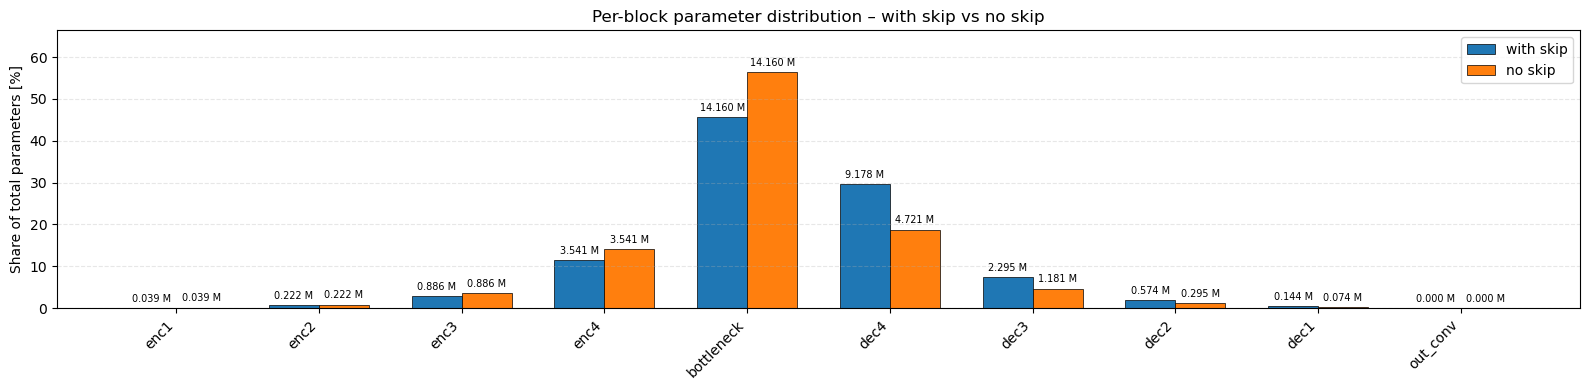

In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1) Build df for the no-skip model (same structure as df_params_blocks)
blocks_order = ["enc1", "enc2", "enc3", "enc4",
                "bottleneck",
                "dec4", "dec3", "dec2", "dec1", "out_conv"]

rows_noskip = []
for b in blocks_order:
    p = params_per_block_noskip[b]
    rows_noskip.append({
        "block": b,
        "params": p,
        "params_M": p / 1e6,
    })

df_params_blocks_noskip = pd.DataFrame(rows_noskip)

total_params_blocks_noskip = df_params_blocks_noskip["params"].sum()
df_params_blocks_noskip["share_percent"] = (
    100.0 * df_params_blocks_noskip["params"] / (total_params_blocks_noskip + 1e-12)
)

# 2) Ensure same order for both dataframes
df_skip = df_params_blocks.copy()
df_skip = df_skip.set_index("block").loc[blocks_order].reset_index()

df_noskip = df_params_blocks_noskip.set_index("block").loc[blocks_order].reset_index()

# 3) Comparison plot: per-block share of parameters (with-skip vs no-skip)
def plot_params_per_block_compare(df_skip, df_noskip, figsize=(16, 4)):
    blocks = df_skip["block"].values

    perc_skip    = df_skip["share_percent"].values
    perc_noskip  = df_noskip["share_percent"].values

    paramsM_skip   = df_skip["params_M"].values
    paramsM_noskip = df_noskip["params_M"].values

    x = np.arange(len(blocks))
    width = 0.35

    fig, ax = plt.subplots(figsize=figsize)

    bars_skip = ax.bar(x - width/2, perc_skip, width,
                       label="with skip", edgecolor="black", linewidth=0.5)
    bars_nos  = ax.bar(x + width/2, perc_noskip, width,
                       label="no skip", edgecolor="black", linewidth=0.5)

    # Labels: absolute params on top of each bar
    for i, bar in enumerate(bars_skip):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{paramsM_skip[i]:.3f} M",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    for i, bar in enumerate(bars_nos):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{paramsM_noskip[i]:.3f} M",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(blocks, rotation=45, ha="right")
    ax.set_ylabel("Share of total parameters [%]")
    ax.set_ylim(0, max(perc_skip.max(), perc_noskip.max()) + 10)
    ax.set_title("Per-block parameter distribution – with skip vs no skip")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

plot_params_per_block_compare(df_skip, df_noskip)


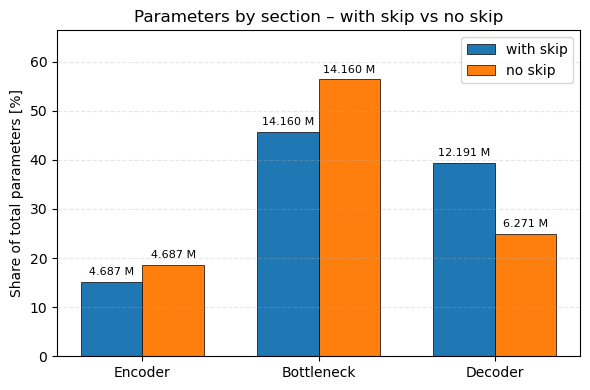

In [56]:
# ---- Macro sections: Encoder / Bottleneck / Decoder ----
encoder_blocks   = ["enc1", "enc2", "enc3", "enc4"]
bottleneck_block = ["bottleneck"]
decoder_blocks   = ["dec4", "dec3", "dec2", "dec1", "out_conv"]

def aggregate_section_params(df_blocks: pd.DataFrame):
    """df_blocks must have columns ['block', 'params', 'params_M']."""
    # Move to index for easy selection
    df_idx = df_blocks.set_index("block")

    def s(blocks):
        p  = df_idx.loc[blocks, "params"].sum()
        pM = df_idx.loc[blocks, "params_M"].sum()
        return p, pM

    rows = []
    for section_name, blocks in [
        ("Encoder",   encoder_blocks),
        ("Bottleneck", bottleneck_block),
        ("Decoder",  decoder_blocks),
    ]:
        p, pM = s(blocks)
        rows.append({"section": section_name, "params": p, "params_M": pM})

    df_sec = pd.DataFrame(rows)
    total_p = df_sec["params"].sum()
    df_sec["share_percent"] = 100.0 * df_sec["params"] / (total_p + 1e-12)
    return df_sec

# Build macro-DFs for with-skip and no-skip
df_macro_skip   = aggregate_section_params(df_skip[["block", "params", "params_M"]])
df_macro_noskip = aggregate_section_params(df_noskip[["block", "params", "params_M"]])

def plot_params_macro_compare(df_skip_macro, df_noskip_macro, figsize=(6, 4)):
    sections = df_skip_macro["section"].values

    perc_skip   = df_skip_macro["share_percent"].values
    perc_noskip = df_noskip_macro["share_percent"].values

    paramsM_skip   = df_skip_macro["params_M"].values
    paramsM_noskip = df_noskip_macro["params_M"].values

    x = np.arange(len(sections))
    width = 0.35

    fig, ax = plt.subplots(figsize=figsize)

    bars_skip = ax.bar(x - width/2, perc_skip, width,
                       label="with skip", edgecolor="black", linewidth=0.5)
    bars_nos  = ax.bar(x + width/2, perc_noskip, width,
                       label="no skip", edgecolor="black", linewidth=0.5)

    # Labels: absolute params on top of each bar
    for i, bar in enumerate(bars_skip):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{paramsM_skip[i]:.3f} M",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    for i, bar in enumerate(bars_nos):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{paramsM_noskip[i]:.3f} M",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(sections)
    ax.set_ylabel("Share of total parameters [%]")
    ax.set_ylim(0, max(perc_skip.max(), perc_noskip.max()) + 10)
    ax.set_title("Parameters by section – with skip vs no skip")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()

plot_params_macro_compare(df_macro_skip, df_macro_noskip, figsize=(6, 4))


#### Per-block time (GPU/CPU) for no-skip

In [57]:
def profile_unet_blocks_time_noskip(
    model: nn.Module,
    input_size=(1, 3, 256, 256),
    device=None,
    n_warmup: int = 5,
    n_runs: int = 50,
):
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    model = model.to(device)
    model.eval()

    times_ms = {
        "enc1": 0.0,
        "enc2": 0.0,
        "enc3": 0.0,
        "enc4": 0.0,
        "bottleneck": 0.0,
        "dec4": 0.0,
        "dec3": 0.0,
        "dec2": 0.0,
        "dec1": 0.0,
        "out_conv": 0.0,
    }

    def sync():
        if device.type == "cuda":
            torch.cuda.synchronize()

    with torch.no_grad():
        x = torch.randn(*input_size, device=device)

        # Warmup
        for _ in range(n_warmup):
            _ = model(x)
        sync()

        for _ in range(n_runs):
            # ----- Encoder -----
            t0 = time.perf_counter()
            enc1 = model.encoder1(x)
            sync()
            t1 = time.perf_counter()
            times_ms["enc1"] += (t1 - t0) * 1000.0

            p1 = model.pool1(enc1)

            t0 = time.perf_counter()
            enc2 = model.encoder2(p1)
            sync()
            t1 = time.perf_counter()
            times_ms["enc2"] += (t1 - t0) * 1000.0

            p2 = model.pool2(enc2)

            t0 = time.perf_counter()
            enc3 = model.encoder3(p2)
            sync()
            t1 = time.perf_counter()
            times_ms["enc3"] += (t1 - t0) * 1000.0

            p3 = model.pool3(enc3)

            t0 = time.perf_counter()
            enc4 = model.encoder4(p3)
            sync()
            t1 = time.perf_counter()
            times_ms["enc4"] += (t1 - t0) * 1000.0

            p4 = model.pool4(enc4)

            # ----- Bottleneck -----
            t0 = time.perf_counter()
            bottleneck = model.bottleneck(p4)
            sync()
            t1 = time.perf_counter()
            times_ms["bottleneck"] += (t1 - t0) * 1000.0

            # ----- Decoder (no skip) -----
            t0 = time.perf_counter()
            y4 = model.upconv4(bottleneck)
            dec4 = model.decoder4(y4)
            sync()
            t1 = time.perf_counter()
            times_ms["dec4"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            y3 = model.upconv3(dec4)
            dec3 = model.decoder3(y3)
            sync()
            t1 = time.perf_counter()
            times_ms["dec3"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            y2 = model.upconv2(dec3)
            dec2 = model.decoder2(y2)
            sync()
            t1 = time.perf_counter()
            times_ms["dec2"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            y1 = model.upconv1(dec2)
            dec1 = model.decoder1(y1)
            sync()
            t1 = time.perf_counter()
            times_ms["dec1"] += (t1 - t0) * 1000.0

            t0 = time.perf_counter()
            out = model.out_conv(dec1)
            sync()
            t1 = time.perf_counter()
            times_ms["out_conv"] += (t1 - t0) * 1000.0

        for k in times_ms:
            times_ms[k] /= n_runs

    return times_ms


# GPU and CPU timings for no-skip model
times_noskip_gpu = profile_unet_blocks_time_noskip(
    noskip_model,
    input_size=NOSKIP_INPUT_SIZE,
    device=DEVICE_GPU,
    n_warmup=NOSKIP_N_WARMUP,
    n_runs=NOSKIP_N_RUNS_GPU,
)

times_noskip_cpu = profile_unet_blocks_time_noskip(
    noskip_model,
    input_size=NOSKIP_INPUT_SIZE,
    device=DEVICE_CPU,
    n_warmup=NOSKIP_N_WARMUP,
    n_runs=NOSKIP_N_RUNS_CPU,
)

print("No-skip U-Net – per-block avg forward time (ms) – GPU:")
for name, t in times_noskip_gpu.items():
    print(f"{name:11s}: {t:.4f} ms")

print("\nNo-skip U-Net – per-block avg forward time (ms) – CPU:")
for name, t in times_noskip_cpu.items():
    print(f"{name:11s}: {t:.4f} ms")

print(f"\nNo-skip total GPU time: {sum(times_noskip_gpu.values()):.4f} ms")
print(f"No-skip total CPU time: {sum(times_noskip_cpu.values()):.4f} ms")


No-skip U-Net – per-block avg forward time (ms) – GPU:
enc1       : 0.2092 ms
enc2       : 0.1797 ms
enc3       : 0.1916 ms
enc4       : 0.3464 ms
bottleneck : 0.8222 ms
dec4       : 0.6504 ms
dec3       : 0.3029 ms
dec2       : 0.2556 ms
dec1       : 0.3680 ms
out_conv   : 0.1066 ms

No-skip U-Net – per-block avg forward time (ms) – CPU:
enc1       : 2.7258 ms
enc2       : 2.7502 ms
enc3       : 1.5706 ms
enc4       : 3.5960 ms
bottleneck : 11.1064 ms
dec4       : 4.6666 ms
dec3       : 5.1989 ms
dec2       : 3.9210 ms
dec1       : 2.9019 ms
out_conv   : 1.4146 ms

No-skip total GPU time: 3.4327 ms
No-skip total CPU time: 39.8521 ms


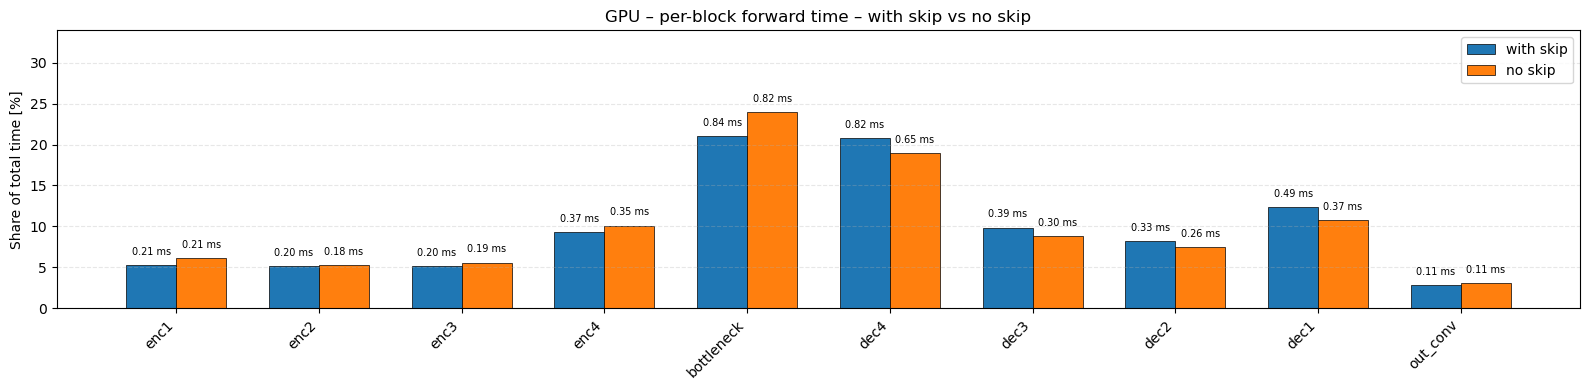

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

blocks_order = ["enc1", "enc2", "enc3", "enc4",
                "bottleneck",
                "dec4", "dec3", "dec2", "dec1", "out_conv"]

# ========= Per-block time comparison (GPU) =========
rows_gpu = []
for b in blocks_order:
    t_skip = times_blocks_gpu_withskip[b]
    t_nos  = times_noskip_gpu[b]
    rows_gpu.append({
        "block": b,
        "time_skip_ms": t_skip,
        "time_noskip_ms": t_nos,
    })

df_time_blocks_gpu_compare = pd.DataFrame(rows_gpu)

# Shares (% of total time) for each model
total_skip_gpu   = df_time_blocks_gpu_compare["time_skip_ms"].sum()
total_noskip_gpu = df_time_blocks_gpu_compare["time_noskip_ms"].sum()

df_time_blocks_gpu_compare["share_skip_percent"] = (
    100.0 * df_time_blocks_gpu_compare["time_skip_ms"] / (total_skip_gpu + 1e-12)
)
df_time_blocks_gpu_compare["share_noskip_percent"] = (
    100.0 * df_time_blocks_gpu_compare["time_noskip_ms"] / (total_noskip_gpu + 1e-12)
)


def plot_time_per_block_compare(df_blocks, figsize=(16, 4), title_prefix="GPU – "):
    blocks = df_blocks["block"].values

    perc_skip   = df_blocks["share_skip_percent"].values
    perc_noskip = df_blocks["share_noskip_percent"].values

    t_skip   = df_blocks["time_skip_ms"].values
    t_noskip = df_blocks["time_noskip_ms"].values

    x = np.arange(len(blocks))
    width = 0.35

    fig, ax = plt.subplots(figsize=figsize)

    bars_skip = ax.bar(x - width/2, perc_skip, width,
                       label="with skip", edgecolor="black", linewidth=0.5)
    bars_nos  = ax.bar(x + width/2, perc_noskip, width,
                       label="no skip", edgecolor="black", linewidth=0.5)

    # Labels: absolute times on top of each bar
    for i, bar in enumerate(bars_skip):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{t_skip[i]:.2f} ms",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    for i, bar in enumerate(bars_nos):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{t_noskip[i]:.2f} ms",
            ha="center",
            va="bottom",
            fontsize=7,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(blocks, rotation=45, ha="right")
    ax.set_ylabel("Share of total time [%]")
    ax.set_ylim(0, max(perc_skip.max(), perc_noskip.max()) + 10)
    ax.set_title(title_prefix + "per-block forward time – with skip vs no skip")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


plot_time_per_block_compare(df_time_blocks_gpu_compare)


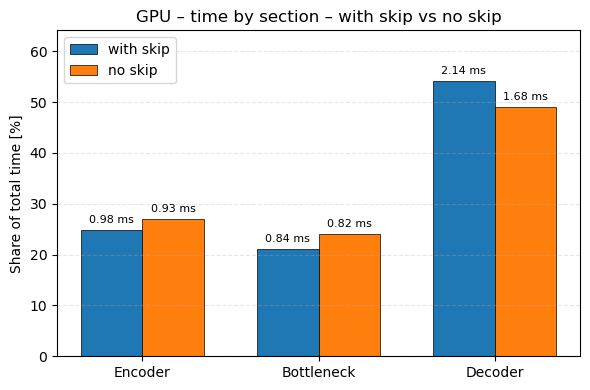

In [59]:
encoder_blocks   = ["enc1", "enc2", "enc3", "enc4"]
bottleneck_block = ["bottleneck"]
decoder_blocks   = ["dec4", "dec3", "dec2", "dec1", "out_conv"]


def aggregate_time_sections(times_dict):
    def s(blocks):
        return sum(times_dict[b] for b in blocks)

    rows = []
    rows.append({"section": "Encoder",   "time_ms": s(encoder_blocks)})
    rows.append({"section": "Bottleneck","time_ms": s(bottleneck_block)})
    rows.append({"section": "Decoder",  "time_ms": s(decoder_blocks)})

    df = pd.DataFrame(rows)
    total = df["time_ms"].sum()
    df["share_percent"] = 100.0 * df["time_ms"] / (total + 1e-12)
    return df


df_time_macro_skip_gpu   = aggregate_time_sections(times_blocks_gpu_withskip)
df_time_macro_noskip_gpu = aggregate_time_sections(times_noskip_gpu)


def plot_time_macro_compare(df_skip_macro, df_noskip_macro,
                            figsize=(6, 4), title_prefix="GPU – "):
    sections = df_skip_macro["section"].values

    perc_skip   = df_skip_macro["share_percent"].values
    perc_noskip = df_noskip_macro["share_percent"].values

    t_skip   = df_skip_macro["time_ms"].values
    t_noskip = df_noskip_macro["time_ms"].values

    x = np.arange(len(sections))
    width = 0.35

    fig, ax = plt.subplots(figsize=figsize)

    bars_skip = ax.bar(x - width/2, perc_skip, width,
                       label="with skip", edgecolor="black", linewidth=0.5)
    bars_nos  = ax.bar(x + width/2, perc_noskip, width,
                       label="no skip", edgecolor="black", linewidth=0.5)

    # Labels: absolute times in ms
    for i, bar in enumerate(bars_skip):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{t_skip[i]:.2f} ms",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    for i, bar in enumerate(bars_nos):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{t_noskip[i]:.2f} ms",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(sections)
    ax.set_ylabel("Share of total time [%]")
    ax.set_ylim(0, max(perc_skip.max(), perc_noskip.max()) + 10)
    ax.set_title(title_prefix + "time by section – with skip vs no skip")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


plot_time_macro_compare(df_time_macro_skip_gpu, df_time_macro_noskip_gpu)


#### FLOPs per block + aggregated summary for no-skip

In [60]:
def compute_flops_per_block_noskip(model: nn.Module, shapes: dict) -> dict:
    """
    FLOPs per block for the no-skip U-Net.
    Uses the same logical block names as before.
    """
    flops_block = {
        "enc1": 0,
        "enc2": 0,
        "enc3": 0,
        "enc4": 0,
        "bottleneck": 0,
        "dec4": 0,
        "dec3": 0,
        "dec2": 0,
        "dec1": 0,
        "out_conv": 0,
    }

    # Encoder blocks
    for name, module in zip(
        ["enc1", "enc2", "enc3", "enc4"],
        [model.encoder1, model.encoder2, model.encoder3, model.encoder4],
    ):
        h, w = shapes[name][2], shapes[name][3]
        for m in module.modules():
            if isinstance(m, nn.Conv2d):
                flops_block[name] += conv2d_flops(m, h, w)
            elif isinstance(m, nn.ConvTranspose2d):
                flops_block[name] += convtranspose2d_flops(m, h, w)

    # Bottleneck
    h, w = shapes["bottleneck"][2], shapes["bottleneck"][3]
    for m in model.bottleneck.modules():
        if isinstance(m, nn.Conv2d):
            flops_block["bottleneck"] += conv2d_flops(m, h, w)
        elif isinstance(m, nn.ConvTranspose2d):
            flops_block["bottleneck"] += convtranspose2d_flops(m, h, w)

    # Decoder blocks
    for name, up_module, dec_module in zip(
        ["dec4", "dec3", "dec2", "dec1"],
        [model.upconv4, model.upconv3, model.upconv2, model.upconv1],
        [model.decoder4, model.decoder3, model.decoder2, model.decoder1],
    ):
        h, w = shapes[name][2], shapes[name][3]
        # upconv
        flops_block[name] += convtranspose2d_flops(up_module, h, w)
        # decoder
        for m in dec_module.modules():
            if isinstance(m, nn.Conv2d):
                flops_block[name] += conv2d_flops(m, h, w)
            elif isinstance(m, nn.ConvTranspose2d):
                flops_block[name] += convtranspose2d_flops(m, h, w)

    # Final 1×1 conv
    h, w = shapes["out"][2], shapes["out"][3]
    for m in model.out_conv.modules():
        if isinstance(m, nn.Conv2d):
            flops_block["out_conv"] += conv2d_flops(m, h, w)
        elif isinstance(m, nn.ConvTranspose2d):
            flops_block["out_conv"] += convtranspose2d_flops(m, h, w)

    return flops_block


flops_noskip = compute_flops_per_block_noskip(noskip_model, shapes_noskip)

print("No-skip U-Net – per-block FLOPs (MFLOPs):")
for name, fl in flops_noskip.items():
    print(f"{name:11s}: {fl / 1e6:.3f} MFLOPs")

print(f"\nNo-skip total FLOPs: {sum(flops_noskip.values()) / 1e6:.3f} MFLOPs")

# Aggregated summary by section (using GPU times here)
summary_noskip = summarize_encoder_bottleneck_decoder(
    times_noskip_gpu,
    flops_noskip,
    params_per_block_noskip,
    encoder_blocks,
    bottleneck_block,
    decoder_blocks,
)

print("\n=== No-skip U-Net summary (GPU) for input", NOSKIP_INPUT_SIZE, "===")
print(f"Time (ms): encoder={summary_noskip['time_encoder_ms']:.3f}, "
      f"bottleneck={summary_noskip['time_bottleneck_ms']:.3f}, "
      f"decoder={summary_noskip['time_decoder_ms']:.3f}, "
      f"total={summary_noskip['time_total_ms']:.3f}")

print(f"Params (M): encoder={summary_noskip['params_encoder'] / 1e6:.3f}, "
      f"bottleneck={summary_noskip['params_bottleneck'] / 1e6:.3f}, "
      f"decoder={summary_noskip['params_decoder'] / 1e6:.3f}, "
      f"total={summary_noskip['params_total'] / 1e6:.3f}")

print(f"FLOPs (M): encoder={summary_noskip['flops_encoder'] / 1e6:.3f}, "
      f"bottleneck={summary_noskip['flops_bottleneck'] / 1e6:.3f}, "
      f"decoder={summary_noskip['flops_decoder'] / 1e6:.3f}, "
      f"total={summary_noskip['flops_total'] / 1e6:.3f}")


No-skip U-Net – per-block FLOPs (MFLOPs):
enc1       : 1264.583 MFLOPs
enc2       : 1811.939 MFLOPs
enc3       : 1811.939 MFLOPs
enc4       : 1811.939 MFLOPs
bottleneck : 1811.939 MFLOPs
dec4       : 3489.661 MFLOPs
dec3       : 3489.661 MFLOPs
dec2       : 3489.661 MFLOPs
dec1       : 3489.661 MFLOPs
out_conv   : 4.194 MFLOPs

No-skip total FLOPs: 22475.178 MFLOPs

=== No-skip U-Net summary (GPU) for input (1, 3, 128, 128) ===
Time (ms): encoder=0.927, bottleneck=0.822, decoder=1.684, total=3.433
Params (M): encoder=4.687, bottleneck=14.160, decoder=6.271, total=25.118
FLOPs (M): encoder=6700.401, bottleneck=1811.939, decoder=13962.838, total=22475.178


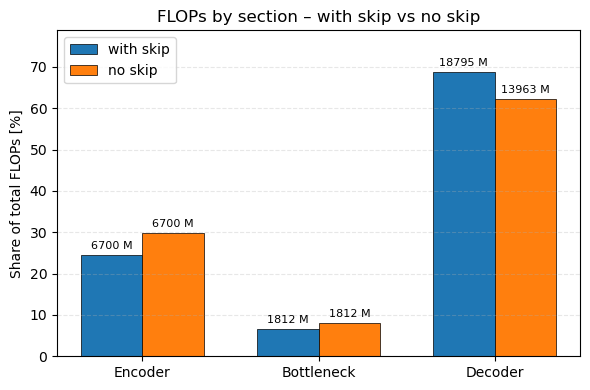

In [61]:
# Using the same encoder/bottleneck/decoder groups as for time/params
encoder_blocks   = ["enc1", "enc2", "enc3", "enc4"]
bottleneck_block = ["bottleneck"]
decoder_blocks   = ["dec4", "dec3", "dec2", "dec1", "out_conv"]

def aggregate_flops_sections(flops_dict):
    def s(blocks):
        return sum(flops_dict[b] for b in blocks) / 1e6  # MFLOPs

    rows = []
    rows.append({"section": "Encoder",   "flops_M": s(encoder_blocks)})
    rows.append({"section": "Bottleneck","flops_M": s(bottleneck_block)})
    rows.append({"section": "Decoder",  "flops_M": s(decoder_blocks)})

    df = pd.DataFrame(rows)
    total = df["flops_M"].sum()
    df["share_percent"] = 100.0 * df["flops_M"] / (total + 1e-12)
    return df

df_flops_macro_skip   = aggregate_flops_sections(flops_blocks_withskip)
df_flops_macro_noskip = aggregate_flops_sections(flops_noskip)


def plot_flops_macro_compare(df_skip_macro, df_noskip_macro,
                             figsize=(6, 4)):
    sections = df_skip_macro["section"].values

    perc_skip   = df_skip_macro["share_percent"].values
    perc_noskip = df_noskip_macro["share_percent"].values

    f_skip_M   = df_skip_macro["flops_M"].values
    f_noskip_M = df_noskip_macro["flops_M"].values

    x = np.arange(len(sections))
    width = 0.35

    fig, ax = plt.subplots(figsize=figsize)

    bars_skip = ax.bar(x - width/2, perc_skip, width,
                       label="with skip", edgecolor="black", linewidth=0.5)
    bars_nos  = ax.bar(x + width/2, perc_noskip, width,
                       label="no skip", edgecolor="black", linewidth=0.5)

    # Labels: absolute FLOPs in MFLOPs
    for i, bar in enumerate(bars_skip):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{f_skip_M[i]:.0f} M",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    for i, bar in enumerate(bars_nos):
        h = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2.0,
            h + 1.0,
            f"{f_noskip_M[i]:.0f} M",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    ax.set_xticks(x)
    ax.set_xticklabels(sections)
    ax.set_ylabel("Share of total FLOPs [%]")
    ax.set_ylim(0, max(perc_skip.max(), perc_noskip.max()) + 10)
    ax.set_title("FLOPs by section – with skip vs no skip")
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend()

    plt.tight_layout()
    plt.show()


plot_flops_macro_compare(df_flops_macro_skip, df_flops_macro_noskip)


In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1) Rebuild summaries for with-skip and no-skip (GPU, same input size)
# ============================================================

# Baseline (with-skip) summary on GPU using backed-up dicts
summary_withskip_256 = summarize_encoder_bottleneck_decoder(
    times_blocks_gpu_withskip,
    flops_blocks_withskip,
    params_per_block_withskip,
    encoder_blocks,
    bottleneck_block,
    decoder_blocks,
)

# No-skip summary on GPU was already computed above:
# summary_noskip = summarize_encoder_bottleneck_decoder(...)
summary_noskip_256 = summary_noskip

# ============================================================
# 2) Compact comparison table (GPU, 256×256 / PROFILE_INPUT_SIZE)
# ============================================================

compare_rows = [
    {
        "model": "with_skip",
        "time_total_ms":      summary_withskip_256["time_total_ms"],
        "time_encoder_ms":    summary_withskip_256["time_encoder_ms"],
        "time_bottleneck_ms": summary_withskip_256["time_bottleneck_ms"],
        "time_decoder_ms":    summary_withskip_256["time_decoder_ms"],
        "flops_total_M":      summary_withskip_256["flops_total"] / 1e6,
        "flops_encoder_M":    summary_withskip_256["flops_encoder"] / 1e6,
        "flops_bottleneck_M": summary_withskip_256["flops_bottleneck"] / 1e6,
        "flops_decoder_M":    summary_withskip_256["flops_decoder"] / 1e6,
        "params_total_M":     summary_withskip_256["params_total"] / 1e6,
        "params_encoder_M":   summary_withskip_256["params_encoder"] / 1e6,
        "params_bottleneck_M":summary_withskip_256["params_bottleneck"] / 1e6,
        "params_decoder_M":   summary_withskip_256["params_decoder"] / 1e6,
    },
    {
        "model": "no_skip",
        "time_total_ms":      summary_noskip_256["time_total_ms"],
        "time_encoder_ms":    summary_noskip_256["time_encoder_ms"],
        "time_bottleneck_ms": summary_noskip_256["time_bottleneck_ms"],
        "time_decoder_ms":    summary_noskip_256["time_decoder_ms"],
        "flops_total_M":      summary_noskip_256["flops_total"] / 1e6,
        "flops_encoder_M":    summary_noskip_256["flops_encoder"] / 1e6,
        "flops_bottleneck_M": summary_noskip_256["flops_bottleneck"] / 1e6,
        "flops_decoder_M":    summary_noskip_256["flops_decoder"] / 1e6,
        "params_total_M":     summary_noskip_256["params_total"] / 1e6,
        "params_encoder_M":   summary_noskip_256["params_encoder"] / 1e6,
        "params_bottleneck_M":summary_noskip_256["params_bottleneck"] / 1e6,
        "params_decoder_M":   summary_noskip_256["params_decoder"] / 1e6,
    },
]

df_compare_256 = pd.DataFrame(compare_rows)
df_compare_256


,model,time_total_ms,time_encoder_ms,time_bottleneck_ms,time_decoder_ms,flops_total_M,flops_encoder_M,flops_bottleneck_M,flops_decoder_M,params_total_M,params_encoder_M,params_bottleneck_M,params_decoder_M
0,with_skip,3.964211,0.984572,0.835034,2.144605,27307.016192,6700.40064,1811.939328,18794.676224,31.037698,4.687296,14.159872,12.19053
1,no_skip,3.432743,0.926947,0.822208,1.683588,22475.177984,6700.40064,1811.939328,13962.838016,25.118018,4.687296,14.159872,6.27085


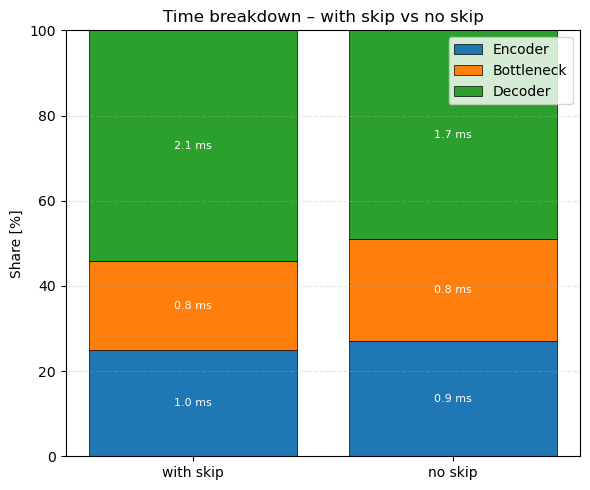

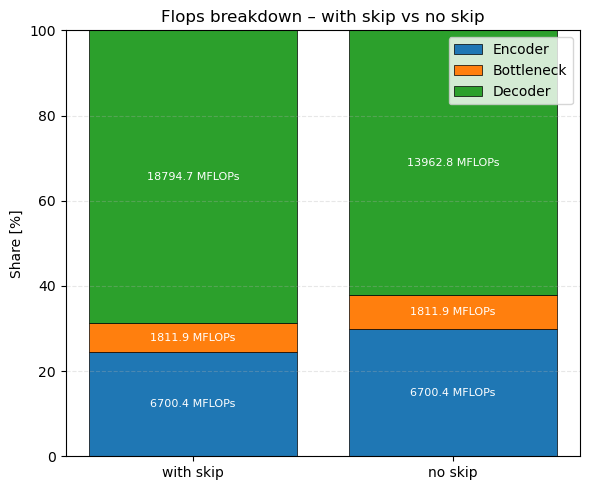

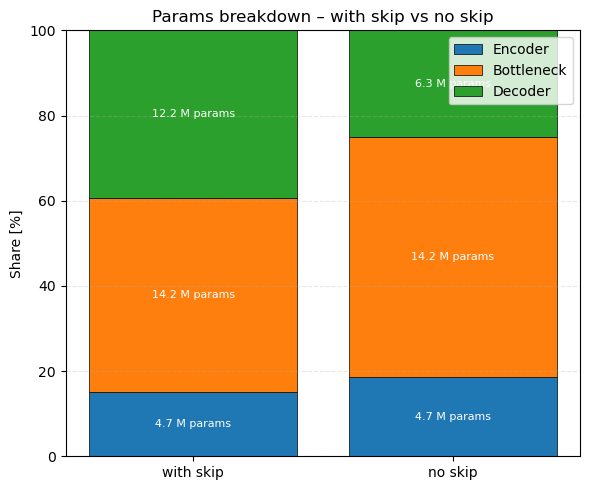

In [63]:
# ============================================================
# 3) Encoder / Bottleneck / Decoder breakdown: with-skip vs no-skip
#    (Uses breakdown_from_summary defined in Part 6)
# ============================================================

def breakdown_from_summary(summary: dict, metric: str = "time"):
    """
    summary: dict from summarize_encoder_bottleneck_decoder(...)
    metric:  "time", "flops", or "params"

    Returns:
        abs_vals: [encoder, bottleneck, decoder] in *raw units*
                  (ms for time, FLOPs, params)
        percents: same, but in % of total
    """
    if metric == "time":
        keys = ["time_encoder_ms", "time_bottleneck_ms", "time_decoder_ms"]
        total_key = "time_total_ms"
    elif metric == "flops":
        keys = ["flops_encoder", "flops_bottleneck", "flops_decoder"]
        total_key = "flops_total"
    elif metric == "params":
        keys = ["params_encoder", "params_bottleneck", "params_decoder"]
        total_key = "params_total"
    else:
        raise ValueError(f"Unknown metric: {metric}")

    raw_vals = np.array([summary[k] for k in keys], dtype=float)
    total = summary[total_key]
    percents = 100.0 * raw_vals / (total + 1e-12)

    # abs_vals are kept in raw units here:
    #   - ms          for time
    #   - FLOPs       for flops
    #   - parameters  for params
    abs_vals = raw_vals
    return abs_vals, percents


def breakdown_for_model(summary, metric="time"):
    abs_vals, perc = breakdown_from_summary(summary, metric=metric)

    # Convert *here* to nicer units for display
    if metric == "flops":
        abs_vals = abs_vals / 1e6   # FLOPs -> MFLOPs
    elif metric == "params":
        abs_vals = abs_vals / 1e6   # params -> M params

    return abs_vals, perc


def plot_ebd_percent_by_model(summary_withskip,
                              summary_noskip,
                              metric="time",
                              unit=None,
                              labels=("with skip", "no skip"),
                              figsize=(6, 5)):
    """
    Compare Encoder/Bottleneck/Decoder share (in %) between two models
    at the same resolution (PROFILE_INPUT_SIZE).
    """
    if unit is None:
        if metric == "time":
            unit = "ms"
        elif metric == "flops":
            unit = "MFLOPs"
        elif metric == "params":
            unit = "M params"

    vals_w, perc_w = breakdown_for_model(summary_withskip, metric)
    vals_n, perc_n = breakdown_for_model(summary_noskip, metric)

    abs_values = np.stack([vals_w, vals_n], axis=0)    # (2, 3)
    perc_values = np.stack([perc_w, perc_n], axis=0)   # (2, 3)

    ebd_labels = ["Encoder", "Bottleneck", "Decoder"]
    colors = ["tab:blue", "tab:orange", "tab:green"]
    indices = np.arange(2)

    fig, ax = plt.subplots(figsize=figsize)
    bottom = np.zeros(2)

    for i in range(3):
        perc_i = perc_values[:, i]
        vals_i = abs_values[:, i]

        bars = ax.bar(
            indices,
            perc_i,
            bottom=bottom,
            label=ebd_labels[i],
            color=colors[i],
            edgecolor="black",
            linewidth=0.5,
        )

        # Annotate reasonably large segments
        for j, bar in enumerate(bars):
            if perc_i[j] < 5:
                continue
            h = bar.get_height()
            y_pos = bar.get_y() + h / 2.0
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                y_pos,
                f"{vals_i[j]:.1f} {unit}",
                ha="center",
                va="center",
                fontsize=8,
                color="white",
            )

        bottom += perc_i

    ax.set_xticks(indices)
    ax.set_xticklabels(labels)
    ax.set_ylabel("Share [%]")
    ax.set_ylim(0, 100)
    ax.set_title(f"{metric.capitalize()} breakdown – with skip vs no skip")
    ax.legend(loc="upper right", frameon=True)
    ax.grid(axis="y", linestyle="--", alpha=0.3)

    plt.tight_layout()
    plt.show()


# Time breakdown (GPU)
plot_ebd_percent_by_model(
    summary_withskip=summary_withskip_256,
    summary_noskip=summary_noskip_256,
    metric="time",
    unit="ms",
    labels=("with skip", "no skip"),
)

# FLOPs breakdown (GPU)
plot_ebd_percent_by_model(
    summary_withskip=summary_withskip_256,
    summary_noskip=summary_noskip_256,
    metric="flops",
    unit="MFLOPs",
    labels=("with skip", "no skip"),
)

# Params breakdown
plot_ebd_percent_by_model(
    summary_withskip=summary_withskip_256,
    summary_noskip=summary_noskip_256,
    metric="params",
    unit="M params",
    labels=("with skip", "no skip"),
)


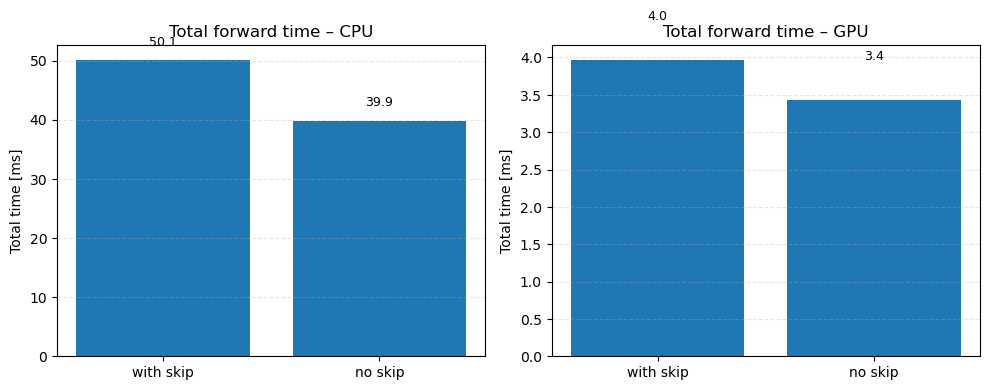

In [64]:
# ============================================================
# 4) Total CPU / GPU forward time: with-skip vs no-skip
#    (reuse existing per-block timings, no extra benchmarking)
# ============================================================

models_labels = ["with skip", "no skip"]

# GPU totals from summaries
total_gpu_withskip = summary_withskip_256["time_total_ms"]
total_gpu_noskip   = summary_noskip_256["time_total_ms"]

# CPU totals from per-block timings
total_cpu_withskip = sum(times_blocks_cpu_withskip.values())
total_cpu_noskip   = sum(times_noskip_cpu.values())

cpu_means = [total_cpu_withskip, total_cpu_noskip]
gpu_means = [total_gpu_withskip, total_gpu_noskip]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# CPU
axes[0].bar(models_labels, cpu_means, color="tab:blue")
axes[0].set_title("Total forward time – CPU")
axes[0].set_ylabel("Total time [ms]")
for i, v in enumerate(cpu_means):
    axes[0].text(i, v + 2, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)

# GPU
axes[1].bar(models_labels, gpu_means, color="tab:blue")
axes[1].set_title("Total forward time – GPU")
axes[1].set_ylabel("Total time [ms]")
for i, v in enumerate(gpu_means):
    axes[1].text(i, v + 0.5, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


## Part 6: Conv vs Transpose-Conv

In [65]:
import torch
import torch.nn as nn
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------------------
# Enc2 / Dec2 like blocks (Carvana-style UNet)
# -----------------------------------------------
class EncLevel2Like(nn.Module):
    """
    Encoder level-2-like block:
      - DoubleConv: 64 -> 128 (two 3x3 convs)
      - MaxPool2d(2)
    Channels follow a standard UNet: 64, 128, 256, 512, 1024
    """
    def __init__(self, in_ch=64, out_ch=128):
        super().__init__()
        self.conv_block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        x = self.conv_block(x)
        x_pooled = self.pool(x)
        return x_pooled


class DecLevel2Like(nn.Module):
    """
    Decoder level-2-like block:
      - ConvTranspose2d: 256 -> 128
      - DoubleConv: 128 -> 128 (two 3x3 convs)
    """
    def __init__(self, in_ch=256, out_ch=128):
        super().__init__()
        self.upconv = nn.ConvTranspose2d(in_ch, out_ch, kernel_size=2, stride=2)
        self.conv_block = nn.Sequential(
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        x = self.upconv(x)
        x = self.conv_block(x)
        return x


def count_params_M(module: nn.Module) -> float:
    return sum(p.numel() for p in module.parameters()) / 1e6


def sync_device(device):
    if device.type == "cuda":
        torch.cuda.synchronize()


def profile_block_ops(enc_block: EncLevel2Like,
                      dec_block: DecLevel2Like,
                      H_level2: int,
                      device: torch.device,
                      n_warmup: int = 10,
                      n_runs: int = 50):
    """
    Profile:
      - enc2-like: DoubleConv vs MaxPool
      - dec2-like: ConvTranspose vs DoubleConv
    Returns a DataFrame with params, FLOPs, and time per component.
    """
    enc_block = enc_block.to(device).eval()
    dec_block = dec_block.to(device).eval()

    rows = []

    with torch.no_grad():
        # ---------------- ENC2-like ----------------
        # Input resolution at level 2 (for Carvana-like UNet)
        x_enc = torch.randn(1, 64, H_level2, H_level2, device=device)

        # Extract conv modules for FLOPs
        conv1_enc = enc_block.conv_block[0]
        conv2_enc = enc_block.conv_block[3]
        # Pool
        pool_enc = enc_block.pool

        # FLOPs (conv only; pool cost is negligible and set to 0)
        flops_enc_conv1 = conv2d_flops(conv1_enc, H_level2, H_level2)
        flops_enc_conv2 = conv2d_flops(conv2_enc, H_level2, H_level2)
        flops_enc_double = flops_enc_conv1 + flops_enc_conv2
        flops_enc_pool = 0.0

        # Params
        params_enc_double = count_params_M(conv1_enc) + count_params_M(conv2_enc)
        params_enc_pool = 0.0

        # Warmup enc-block
        for _ in range(n_warmup):
            y = enc_block.conv_block(x_enc)
            y_p = pool_enc(y)
        sync_device(device)

        # Time double conv
        t0 = time.perf_counter()
        for _ in range(n_runs):
            y = enc_block.conv_block(x_enc)
        sync_device(device)
        t1 = time.perf_counter()
        time_enc_double_ms = (t1 - t0) * 1000.0 / n_runs

        # Time pool only (on a tensor shaped like conv output)
        x_pool = torch.randn(1, 128, H_level2, H_level2, device=device)
        t0 = time.perf_counter()
        for _ in range(n_runs):
            y_p = pool_enc(x_pool)
        sync_device(device)
        t1 = time.perf_counter()
        time_enc_pool_ms = (t1 - t0) * 1000.0 / n_runs

        rows.append({
            "block": "enc2_doubleconv",
            "params_M": params_enc_double,
            "flops_M": flops_enc_double / 1e6,
            "time_ms": time_enc_double_ms,
        })
        rows.append({
            "block": "enc2_pool",
            "params_M": params_enc_pool,
            "flops_M": flops_enc_pool / 1e6,
            "time_ms": time_enc_pool_ms,
        })

        # ---------------- DEC2-like ----------------
        # Input resolution at level 3 for decoder (downsampled once w.r.t. level2)
        H_level3 = H_level2 // 2
        x_dec = torch.randn(1, 256, H_level3, H_level3, device=device)

        up = dec_block.upconv
        conv1_dec = dec_block.conv_block[0]
        conv2_dec = dec_block.conv_block[3]

        # FLOPs
        flops_dec_up = convtranspose2d_flops(up, H_level2, H_level2)
        flops_dec_conv1 = conv2d_flops(conv1_dec, H_level2, H_level2)
        flops_dec_conv2 = conv2d_flops(conv2_dec, H_level2, H_level2)
        flops_dec_double = flops_dec_conv1 + flops_dec_conv2

        # Params
        params_dec_up = count_params_M(up)
        params_dec_double = count_params_M(conv1_dec) + count_params_M(conv2_dec)

        # Warmup
        for _ in range(n_warmup):
            y_up = up(x_dec)
            y_dec = dec_block.conv_block(y_up)
        sync_device(device)

        # Time upconv only
        t0 = time.perf_counter()
        for _ in range(n_runs):
            y_up = up(x_dec)
        sync_device(device)
        t1 = time.perf_counter()
        time_dec_up_ms = (t1 - t0) * 1000.0 / n_runs

        # Time double conv (on tensor shaped like upconv output)
        x_dec_conv = torch.randn(1, 128, H_level2, H_level2, device=device)
        t0 = time.perf_counter()
        for _ in range(n_runs):
            y_dec = dec_block.conv_block(x_dec_conv)
        sync_device(device)
        t1 = time.perf_counter()
        time_dec_double_ms = (t1 - t0) * 1000.0 / n_runs

        rows.append({
            "block": "dec2_upconv",
            "params_M": params_dec_up,
            "flops_M": flops_dec_up / 1e6,
            "time_ms": time_dec_up_ms,
        })
        rows.append({
            "block": "dec2_doubleconv",
            "params_M": params_dec_double,
            "flops_M": flops_dec_double / 1e6,
            "time_ms": time_dec_double_ms,
        })

    return pd.DataFrame(rows)


In [66]:
# -----------------------------------------------
# Run enc2 vs dec2 detailed analysis
# -----------------------------------------------

# Level-2 spatial resolution for the current PROFILE_INPUT_SIZE
# Example: for 512×512 input, level2 feature maps are 512 / 4 = 128
H_level2 = PROFILE_INPUT_SIZE[2] // 4

enc2_block = EncLevel2Like(in_ch=64, out_ch=128)
dec2_block = DecLevel2Like(in_ch=256, out_ch=128)

df_enc_dec_ops = profile_block_ops(
    enc_block=enc2_block,
    dec_block=dec2_block,
    H_level2=H_level2,
    device=DEVICE_GPU,
    n_warmup=10,
    n_runs=50,
)

df_enc_dec_ops


,block,params_M,flops_M,time_ms
0,enc2_doubleconv,0.221184,452.984832,0.224006
1,enc2_pool,0.000000,0.000000,0.017323
2,dec2_upconv,0.131200,268.435456,0.053203
3,dec2_doubleconv,0.294912,603.979776,0.156321


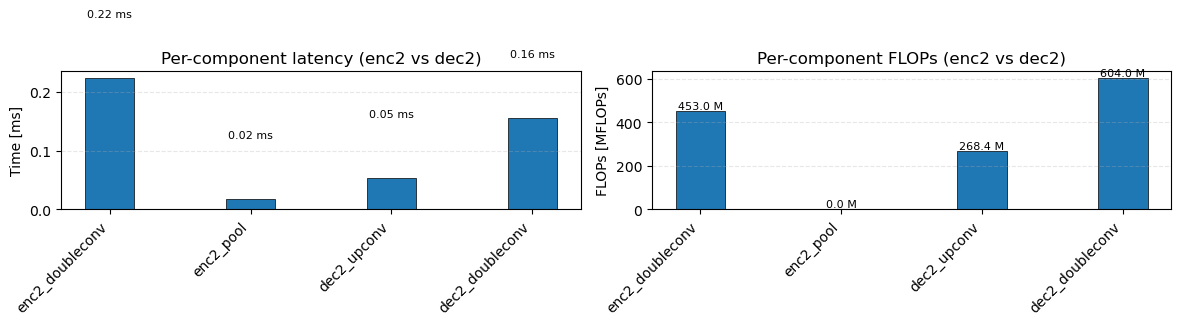

In [67]:
# -----------------------------------------------
# Visualise time and FLOPs per component
# -----------------------------------------------
blocks = df_enc_dec_ops["block"].values
times  = df_enc_dec_ops["time_ms"].values
flops  = df_enc_dec_ops["flops_M"].values

x = np.arange(len(blocks))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Time
ax = axes[0]
bars = ax.bar(x, times, width, edgecolor="black", linewidth=0.5)
for i, bar in enumerate(bars):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0,
            h + 0.1,
            f"{h:.2f} ms",
            ha="center",
            va="bottom",
            fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(blocks, rotation=45, ha="right")
ax.set_ylabel("Time [ms]")
ax.set_title("Per-component latency (enc2 vs dec2)")
ax.grid(axis="y", linestyle="--", alpha=0.3)

# FLOPs
ax = axes[1]
bars = ax.bar(x, flops, width, edgecolor="black", linewidth=0.5)
for i, bar in enumerate(bars):
    h = bar.get_height()
    ax.text(bar.get_x() + bar.get_width() / 2.0,
            h + 0.1,
            f"{h:.1f} M",
            ha="center",
            va="bottom",
            fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(blocks, rotation=45, ha="right")
ax.set_ylabel("FLOPs [MFLOPs]")
ax.set_title("Per-component FLOPs (enc2 vs dec2)")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


,block,params_M,flops_M,time_ms,side,op
0,enc2_doubleconv,0.221184,452.984832,0.224006,encoder,doubleconv
1,enc2_pool,0.000000,0.000000,0.017323,encoder,pool
2,dec2_upconv,0.131200,268.435456,0.053203,decoder,upconv
3,dec2_doubleconv,0.294912,603.979776,0.156321,decoder,doubleconv


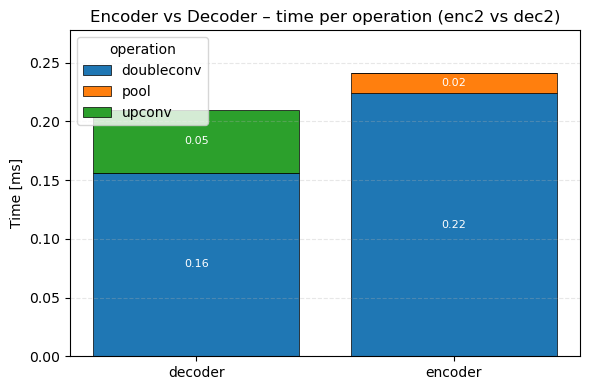

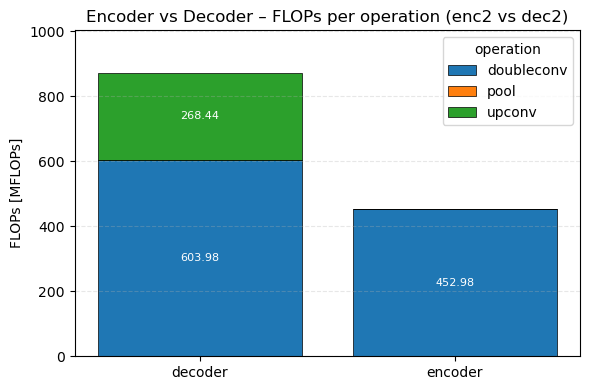

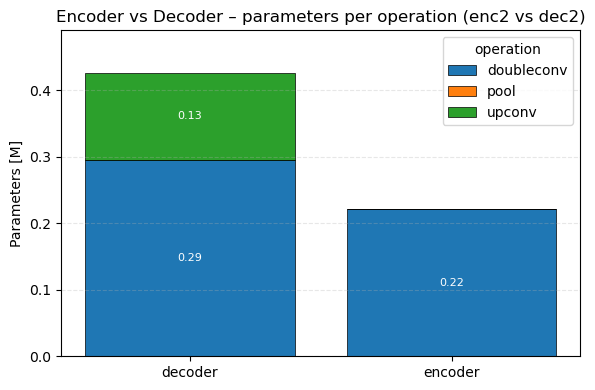

In [68]:
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------
# Enrich df_enc_dec_ops: side (encoder/decoder) + op type
# -------------------------------------------------------
df_ops = df_enc_dec_ops.copy()

def _side_from_block(b):
    return "encoder" if b.startswith("enc") else "decoder"

def _op_from_block(b):
    if "doubleconv" in b:
        return "doubleconv"
    if "pool" in b:
        return "pool"
    if "upconv" in b:
        return "upconv"
    return "other"

df_ops["side"] = df_ops["block"].apply(_side_from_block)
df_ops["op"]   = df_ops["block"].apply(_op_from_block)

display(df_ops)  # optional sanity check


# -------------------------------------------------------
# Helper: stacked bar (encoder vs decoder) – ABSOLUTE values
# -------------------------------------------------------
def plot_side_op_stacked_abs(df_ops, metric, ylabel, title, figsize=(6,4)):
    """
    df_ops: rows = component blocks (enc2_doubleconv, dec2_upconv, etc.)
    metric: 'time_ms', 'flops_M', or 'params_M'
    Shows encoder vs decoder bars, stacked by op type (doubleconv/pool/upconv),
    with ABSOLUTE values on the y-axis.
    """
    # Aggregate: sum(metric) per (side, op)
    pivot = (
        df_ops
        .groupby(["side", "op"], as_index=False)[metric]
        .sum()
        .pivot(index="side", columns="op", values=metric)
        .fillna(0.0)
    )

    # Ensure consistent op order
    op_order = ["doubleconv", "pool", "upconv"]
    op_cols = [c for c in op_order if c in pivot.columns]
    pivot = pivot[op_cols]

    sides = pivot.index.tolist()
    vals  = pivot.values  # shape (n_sides, n_ops)

    x = np.arange(len(sides))
    fig, ax = plt.subplots(figsize=figsize)

    bottom = np.zeros(len(sides))
    colors = {
        "doubleconv": "tab:blue",
        "pool":       "tab:orange",
        "upconv":     "tab:green",
    }

    for i, op in enumerate(op_cols):
        seg = vals[:, i]
        bars = ax.bar(
            x,
            seg,
            bottom=bottom,
            label=op,
            color=colors.get(op, None),
            edgecolor="black",
            linewidth=0.5,
        )

        # Annotate each segment with its absolute value
        for j, bar in enumerate(bars):
            if seg[j] <= 0:
                continue
            h = bar.get_height()
            y_pos = bar.get_y() + h / 2.0
            ax.text(
                bar.get_x() + bar.get_width() / 2.0,
                y_pos,
                f"{seg[j]:.2f}",
                ha="center",
                va="center",
                fontsize=8,
                color="white",
            )

        bottom += seg

    ax.set_xticks(x)
    ax.set_xticklabels(sides)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    ax.legend(title="operation", frameon=True)

    # Small headroom
    ax.set_ylim(0, bottom.max() * 1.15)

    plt.tight_layout()
    plt.show()


# -------------------------------------------------------
# 3 concise plots: time / FLOPs / params (ABSOLUTE)
# -------------------------------------------------------

# 1) Time
plot_side_op_stacked_abs(
    df_ops,
    metric="time_ms",
    ylabel="Time [ms]",
    title="Encoder vs Decoder – time per operation (enc2 vs dec2)"
)

# 2) FLOPs
plot_side_op_stacked_abs(
    df_ops,
    metric="flops_M",
    ylabel="FLOPs [MFLOPs]",
    title="Encoder vs Decoder – FLOPs per operation (enc2 vs dec2)"
)

# 3) Params
plot_side_op_stacked_abs(
    df_ops,
    metric="params_M",
    ylabel="Parameters [M]",
    title="Encoder vs Decoder – parameters per operation (enc2 vs dec2)"
)


Per-block metrics (with-skip Carvana U-Net):
        block  time_gpu_ms  time_cpu_ms       flops_M   params_M
0        enc1     5.568355    56.652592  20233.322496   0.038848
1        enc2     5.590882    70.955132  28991.029248   0.221696
2        enc3     3.855032    54.435746  28991.029248   0.885760
3        enc4     3.824225    50.584452  28991.029248   3.540992
4  bottleneck     4.352864    50.070206  28991.029248  14.159872
5        dec4     8.411715   101.389637  75161.927680   9.177600
6        dec3     8.390285   105.981138  75161.927680   2.295040
7        dec2    11.102729   120.235528  75161.927680   0.574080
8        dec1    14.046139   144.893647  75161.927680   0.143680
9    out_conv     0.584977     5.067018     67.108864   0.000130


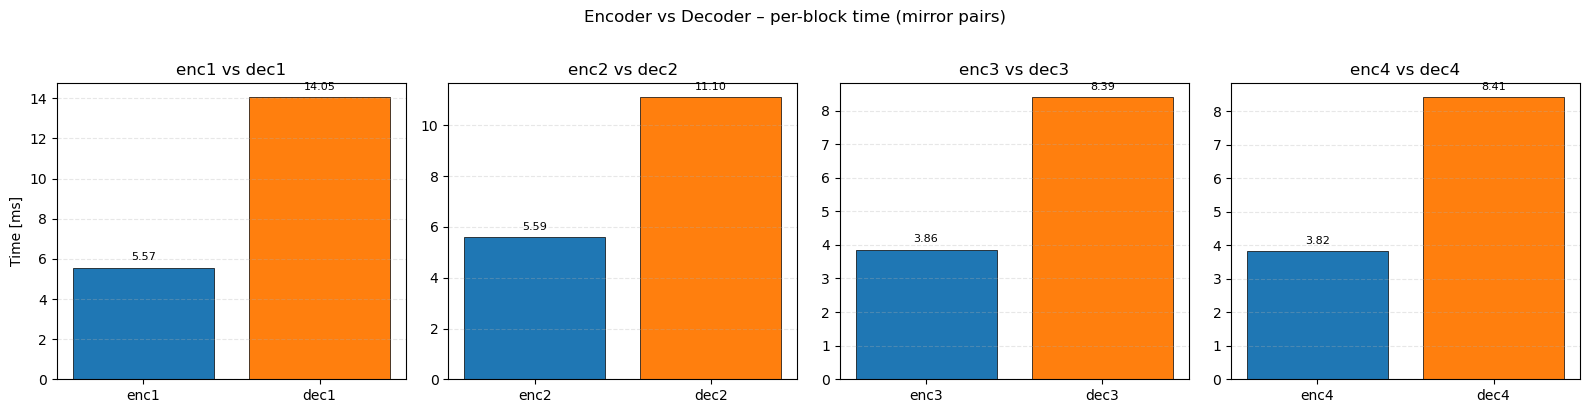

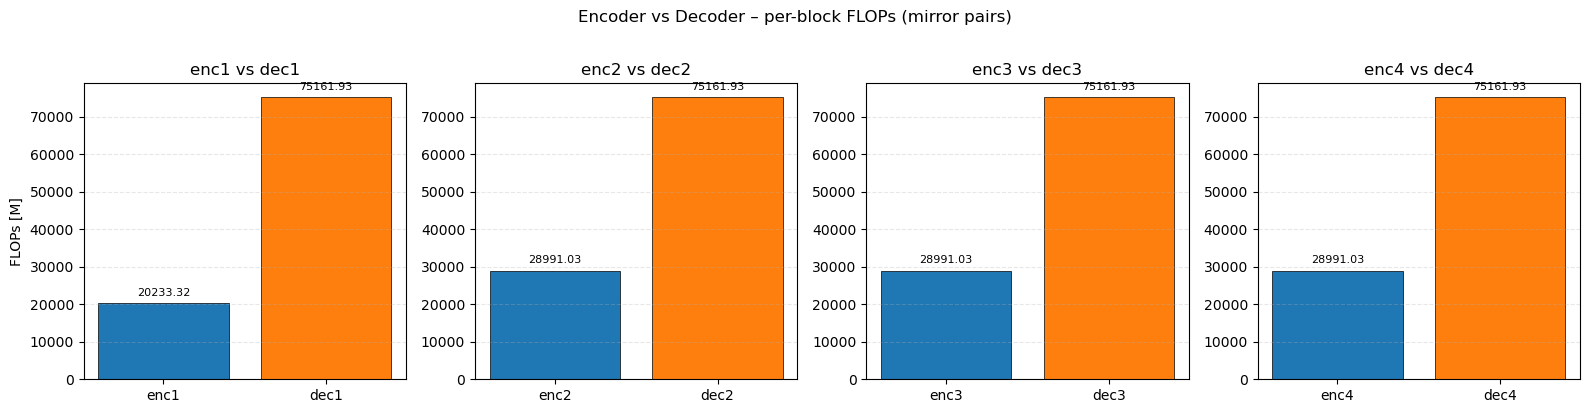

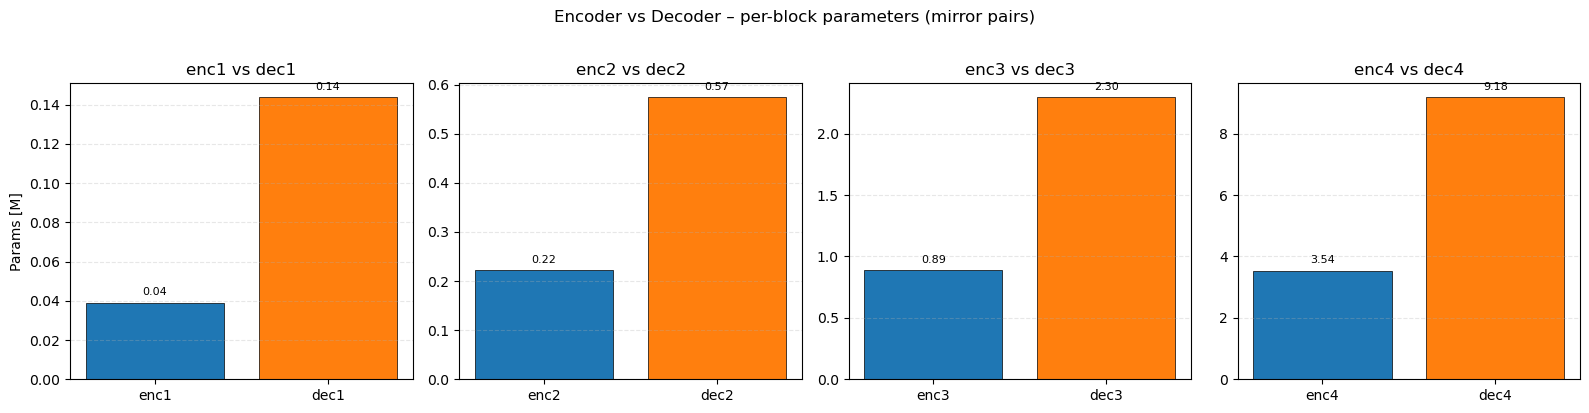

In [97]:
# ===============================================================
# Part 6 – Block-level analysis + ConvTranspose vs Upsample+Conv
# ===============================================================

import torch
import torch.nn as nn
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 6.1. Rebuild per-block table for the baseline (with-skip) U-Net
# ---------------------------------------------------------------

blocks_order = [
    "enc1", "enc2", "enc3", "enc4",
    "bottleneck",
    "dec4", "dec3", "dec2", "dec1",
    "out_conv",
]

df_time_flops_blocks = pd.DataFrame(
    [
        {
            "block": b,
            "time_gpu_ms":  times_blocks_gpu[b],
            "time_cpu_ms":  times_blocks_cpu[b],
            "flops_M":      flops_blocks[b] / 1e6,
            "params_M":     params_per_block_dict[b] / 1e6,
        }
        for b in blocks_order
    ]
)

print("Per-block metrics (with-skip Carvana U-Net):")
print(df_time_flops_blocks)


# ---------------------------------------------------------------
# 6.2. Encoder vs decoder – enc1 vs dec1..dec4 (time/FLOPs/params)
# ---------------------------------------------------------------

def plot_enc_dec_mirror_pairs_all_metrics(df_blocks: pd.DataFrame):
    """
    Compare mirror pairs (enc1–dec1, enc2–dec2, enc3–dec3, enc4–dec4)
    for three metrics:
        - time_gpu_ms
        - flops_M
        - params_M

    For each metric, one figure with 4 subplots (one per pair).
    """
    if "block" not in df_blocks.columns:
        raise ValueError("df_blocks must contain a 'block' column.")

    required_cols = ["time_gpu_ms", "flops_M", "params_M"]
    for c in required_cols:
        if c not in df_blocks.columns:
            raise ValueError(
                f"Column '{c}' not found in df_blocks. Available: {list(df_blocks.columns)}"
            )

    # Mirror pairs in U-Net depth
    pairs = [("enc1", "dec1"),
             ("enc2", "dec2"),
             ("enc3", "dec3"),
             ("enc4", "dec4")]

    metrics = [
        ("time_gpu_ms", "Time [ms]",  "Encoder vs Decoder – per-block time (mirror pairs)"),
        ("flops_M",     "FLOPs [M]",  "Encoder vs Decoder – per-block FLOPs (mirror pairs)"),
        ("params_M",    "Params [M]", "Encoder vs Decoder – per-block parameters (mirror pairs)"),
    ]

    def get_vals_for_pair(enc_block: str, dec_block: str, metric_col: str):
        """Return (val_enc, val_dec) for the given metric and pair."""
        mask = df_blocks["block"].isin([enc_block, dec_block])
        sub = df_blocks[mask]

        vals = {"enc": 0.0, "dec": 0.0}
        for _, row in sub.iterrows():
            b = str(row["block"])
            if b.startswith("enc"):
                vals["enc"] = float(row[metric_col])
            elif b.startswith("dec"):
                vals["dec"] = float(row[metric_col])
        return np.array([vals["enc"], vals["dec"]], dtype=float)

    for metric_col, ylabel, title in metrics:
        fig, axes = plt.subplots(
            1, len(pairs),
            figsize=(4 * len(pairs), 4),
            sharey=False,
        )

        if len(pairs) == 1:
            axes = [axes]

        for idx, (enc_b, dec_b) in enumerate(pairs):
            ax = axes[idx]
            vals = get_vals_for_pair(enc_b, dec_b, metric_col)
            x_pos = np.arange(2)

            bars = ax.bar(
                x_pos,
                vals,
                color=["tab:blue", "tab:orange"],
                edgecolor="black",
                linewidth=0.5,
            )

            max_val = max(vals.max(), 1e-9)
            for i, bar in enumerate(bars):
                h = bar.get_height()
                ax.text(
                    bar.get_x() + bar.get_width() / 2.0,
                    h + 0.02 * max_val,
                    f"{h:.2f}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                )

            ax.set_xticks(x_pos)
            ax.set_xticklabels([enc_b, dec_b])
            ax.set_title(f"{enc_b} vs {dec_b}")
            ax.grid(axis="y", linestyle="--", alpha=0.3)
            if idx == 0:
                ax.set_ylabel(ylabel)

        fig.suptitle(title, y=1.02)
        plt.tight_layout()
        plt.show()


# Run grouped enc1 vs dec1..4 plots
plot_enc_dec_mirror_pairs_all_metrics(df_time_flops_blocks)
